In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score

import os
import pickle

# Computing Clusters with kmeans

In [37]:
df_pre_PCA = pd.read_csv('../PART1/ddos_dataset_pre_PCA.csv', index_col=0)
df_pd = df_pre_PCA.copy()

In [38]:
label_counts = df_pd['label'].value_counts()
df_labels = df_pd['label'].values

In [39]:
# Dropping categorical or useless features
columnsToDrop = ["Flow ID","Source IP", "Source Port", "Destination IP", "Destination Port", "Timestamp","label"]
df_pd = df_pd.drop(columns=columnsToDrop)

In [40]:
df_np = df_pd.to_numpy()
df_pre_kmeans_np = StandardScaler().fit_transform(df_np)
df_pre_kmeans_pd = pd.DataFrame(df_pre_kmeans_np, columns=df_pd.columns)

In [41]:
best_k = 9
randomstate = 42

kmeans = KMeans(n_clusters=best_k, init='k-means++', n_init=10, random_state=randomstate)
kmeans.fit(df_pre_kmeans_np)

df_pd["cluster"] = kmeans.labels_
df_pd["label"] = df_pre_PCA["label"]

In [42]:
# create this folder to save already computed results
if not os.path.exists("./saved_results"):
    os.makedirs("./saved_results")

#  1. Cluster Distribution of Traffic Types

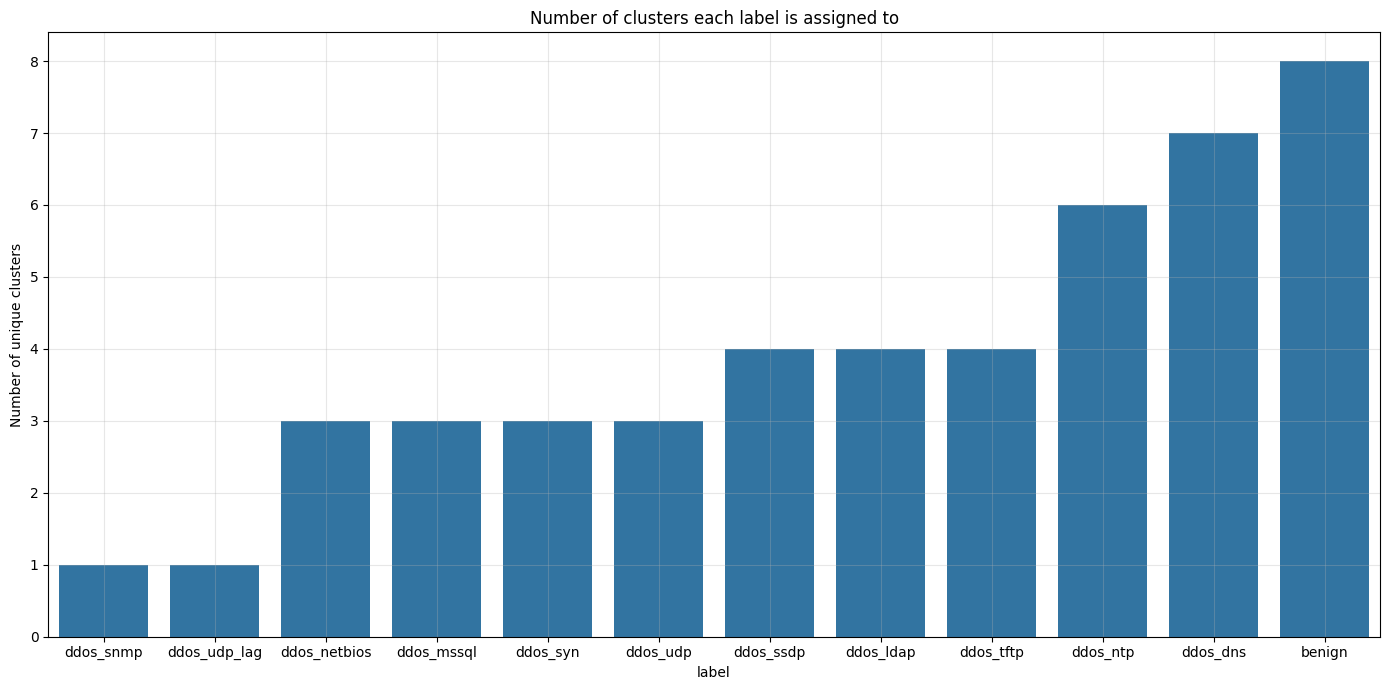

In [43]:
def plot_clusters_per_label(clusters_per_label):
    plt.figure(figsize=(14, 7))
    sns.barplot(x=clusters_per_label.index, y=clusters_per_label.values)

    plt.title('Number of clusters each label is assigned to')
    plt.xlabel('label')
    plt.ylabel('Number of unique clusters')
    
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

clusters_per_label = df_pd.groupby('label')['cluster'].nunique().sort_values()
plot_clusters_per_label(clusters_per_label)

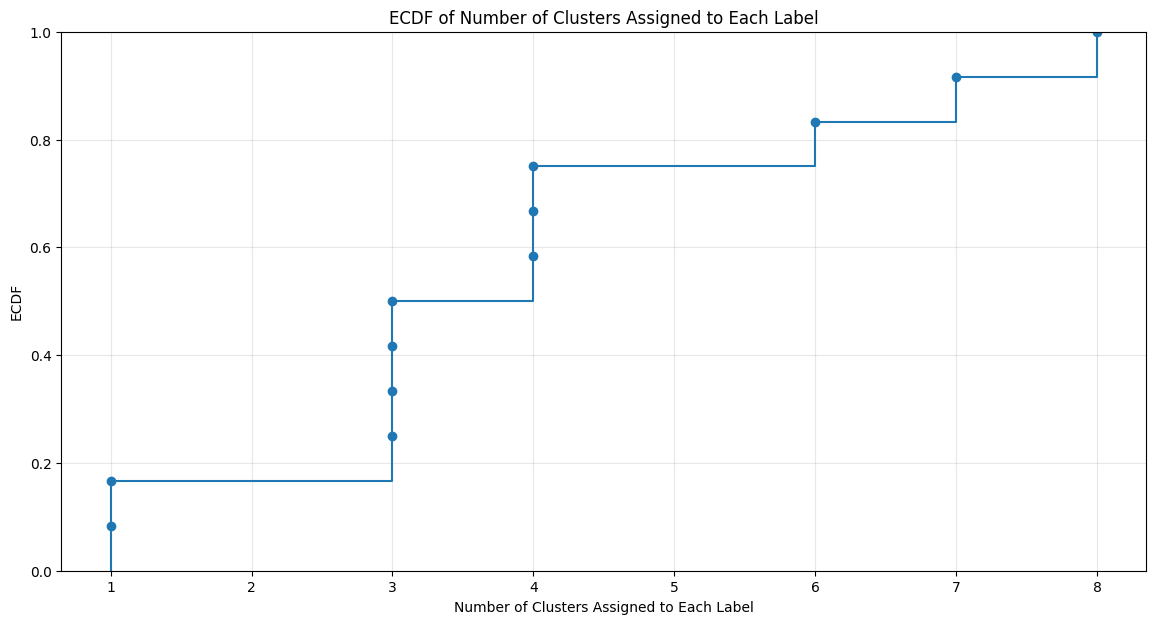

In [44]:
def plot_ECDF_number_of_clusters_per_label(clusters_per_label):
    plt.figure(figsize=(14, 7))
    sns.ecdfplot(clusters_per_label, marker='o')

    plt.title('ECDF of Number of Clusters Assigned to Each Label')
    plt.xlabel('Number of Clusters Assigned to Each Label')
    plt.ylabel('ECDF')
    plt.grid(alpha=0.3)
    plt.show()

plot_ECDF_number_of_clusters_per_label(clusters_per_label)

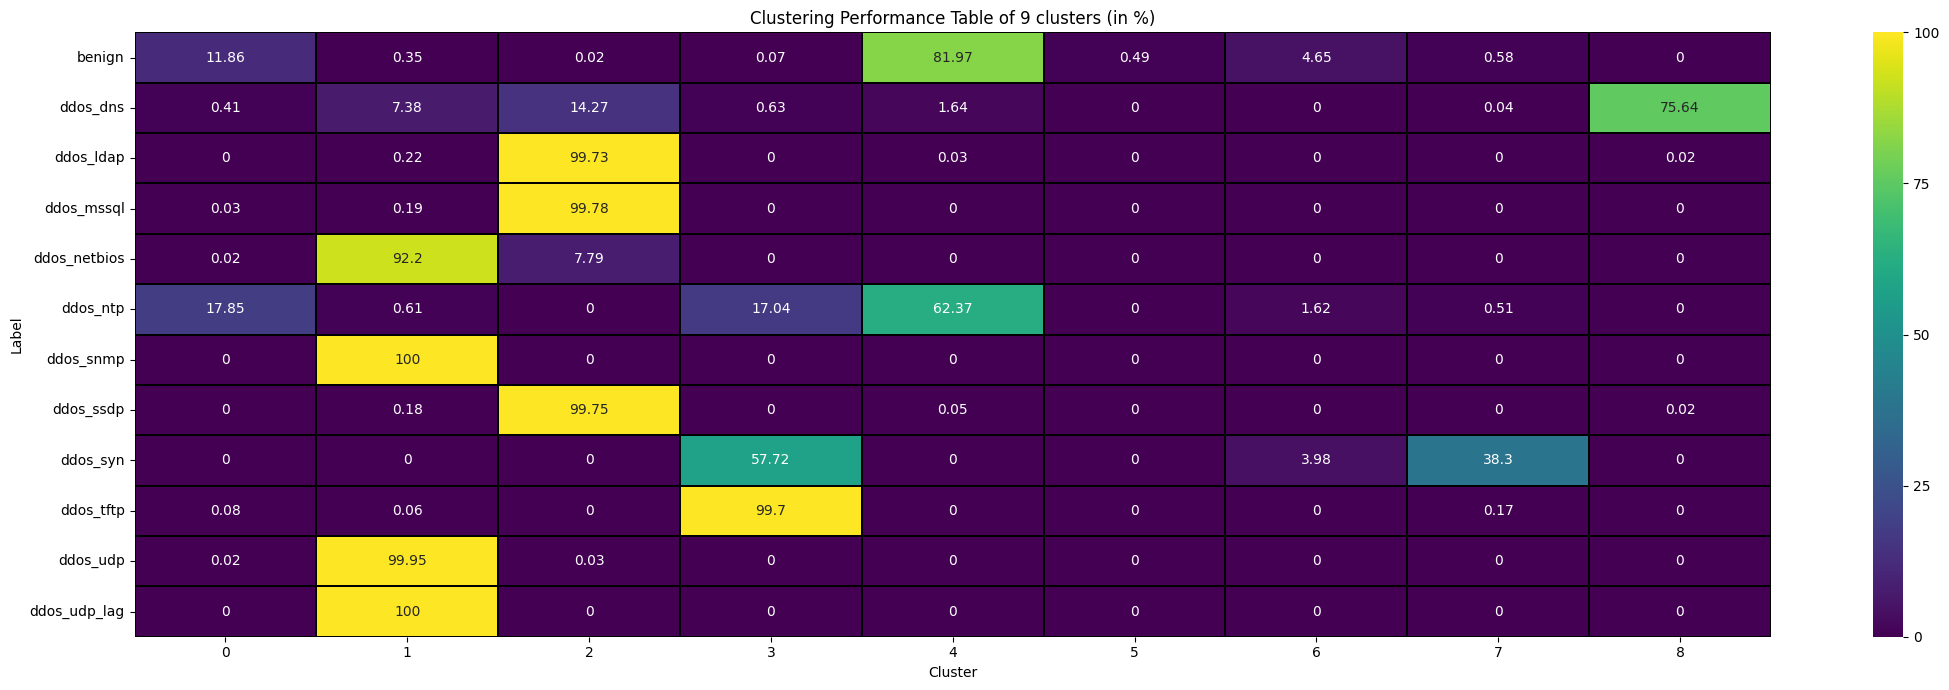

In [45]:
def plot_label_cluster_heatmap(cluster_labels, true_labels, normalize=True):
    df = pd.DataFrame({"label": true_labels,"cluster": cluster_labels})
    table = (df.groupby("label")["cluster"].value_counts().unstack(fill_value=0))

    if normalize:
        table = table.div(table.sum(axis=1), axis=0) *100

    plt.figure(figsize=(22,7))
    sns.heatmap(table, 
                cmap="viridis", 
                cbar=True, 
                cbar_kws={"ticks": np.linspace(0, 100 if normalize else table.values.max(), 5)}, 
                vmin=0, 
                vmax=100 if normalize else table.values.max(), 
                linewidths=0.1, 
                linecolor='black', 
                fmt="", 
                annot=table.map(lambda v: f"{v:.2f}".rstrip('0').rstrip('.')) if normalize else table,
                annot_kws={"size": 10})

    plt.xlabel("Cluster")
    plt.ylabel("Label")
    if normalize:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (in %)")
    else:
        plt.title(f"Clustering Performance Table of {len(np.unique(cluster_labels))} clusters (num of samples)")

    plt.tight_layout()
    plt.show()

plot_label_cluster_heatmap(df_pd["cluster"],df_pd["label"],True)

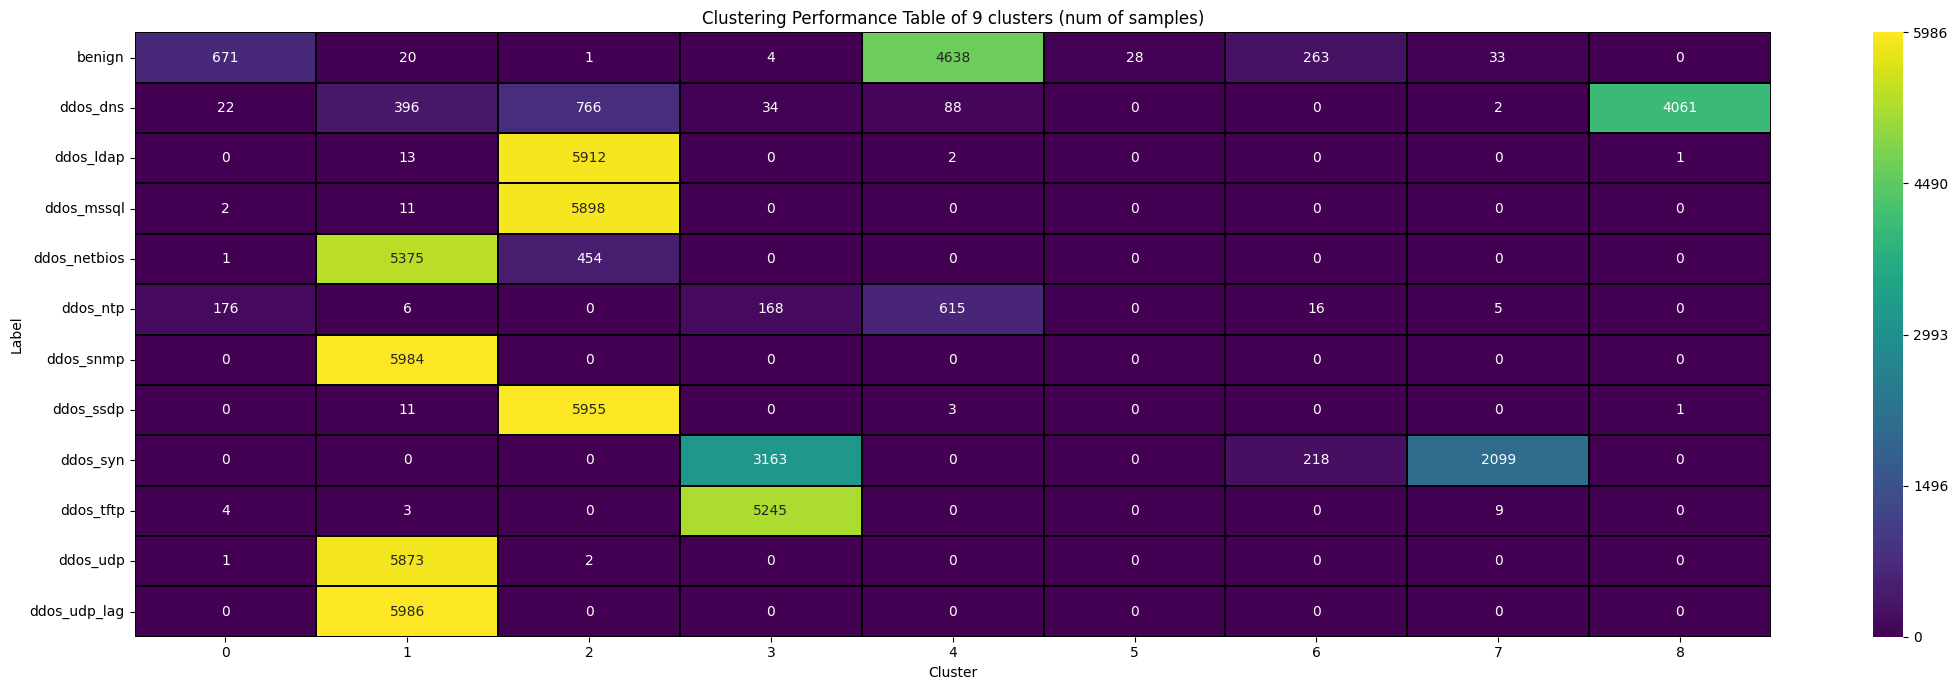

In [46]:
plot_label_cluster_heatmap(df_pd["cluster"],df_pd["label"],False)

# Analysis
1. a) How Traffic is Distributed (ECDF Analysis):
    - The analysis demonstrates that traffic is not uniformly distributed across clusters.
    - ECDF Analysis: The ECDF plot reveals that approximately 75% of the classes are concentrated within 6 or fewer clusters.
    - Fragmentation: There is significant variability in how classes are assigned. For instance, ddos_snmp and ddos_udp_lag are concentrated in only 1 clusters, whereas benign, ddos_ntp, ddos_dns and ddos_syn are the most fragmented.

2. b) Cluster Purity:
    - High Purity Clusters:
        - Cluster 5: Appears to be an empty or nearly empty cluster.
        - Cluster 7: Highly specific to ddos_syn (38.30%).
        - Cluster 8: Highly specific to ddos_dns (75.64%).
    - Low Purity/Mixed Clusters:
        - Cluster 1: Dominated by ddos_snmp, ddos_udp, ddos_netbios and ddos_udp_lag (all near 100%). However, this cluster is "impure" in the sense that it merges three different malicious labels.
        - Cluster 2: Heavily shared between ddos_ldap, ddos_mssql, and ddos_ssdp (all >99%). This shows that the algorithm cannot distinguish between these three types of DDoS attacks.
        - Cluster 4: Contains a mix of benign (81.97%) and ddos_ntp (62.37%).

3. c) GT Reflection and Benign-Malicious Overlaps:
    - The clusters partially reflect Ground Truth Labels. The clustering successfully separates "groups" of attacks (e.g., LDAP/MSSQL/SSDP are grouped together in Cluster 2)
    - Benign vs. Malicious Similarity: There is clear evidence that benign traffic shares characteristics with malicious traffic:
        - Cluster 4 is a primary example where benign traffic and ddos_ntp traffic are grouped together.
        - Cluster 0 also shows a significant overlap where benign (11.86%) and ddos_ntp (17.85%) coexist.
        - Cluster 6 also shows a significant overlap where benign (4.65%), ddos_ntp (1.62%) and ddos_syn (3.98%) coexist.
        - This suggests that the features of NTP-based attacks are very similar to benign network activity.

# 2. Feature Importance Analysis.

### Permutation Importance

In [47]:
def permutation_importance_kmeans(checkpoint_file, df, features, true_labels, n_clusters, n_repeats=10, random_state=42, n_sample = None):
    if os.path.exists(checkpoint_file):
        with open(checkpoint_file, "rb") as f:
            saved_info = pickle.load(f)
            results = saved_info["results"]
            baseline = saved_info["baseline"]
            rng = np.random.default_rng()
            rng.bit_generator.state = saved_info["rng_state"]
            n_f = len(results["features"])
            print(f"Checkpoint found. Feature processed: {n_f}")
    else:
        rng = np.random.default_rng(random_state)
        kmeans_baseline = KMeans(n_clusters=n_clusters, init='k-means++', n_init=10, random_state=random_state)
        baseline_labels = kmeans_baseline.fit_predict(df)

        baseline = {
            "labels": baseline_labels,
            "ari": adjusted_rand_score(true_labels, baseline_labels),
            "ri": rand_score(true_labels, baseline_labels),
            "inertia": kmeans_baseline.inertia_,
            "inertia_per_sample": kmeans_baseline.inertia_ / len(df),
            "silhouette": silhouette_score(df, baseline_labels, sample_size=n_sample ),
            "cluster_count": np.bincount(baseline_labels, minlength=n_clusters)
        }

        results = {
            "features": [],
            "ari": [],
            "ri": [],
            "inertia": [],
            "inertia_per_sample": [],
            "silhouette": [],
            "cluster_count_variation": [],
            "instability_scores": []
        }

    for j in range(df.shape[1]):
        if features[j] not in results["features"]:
            print(f"Iterating on {features[j]}")
            ari_scores = []
            ri_scores = []
            inertia_scores = []
            inertia_per_sample_scores = []
            silhouette_scores = []
            cluster_count_variation = []
            instability_scores = []

            for l in range(n_repeats):
                df_perm = df.copy()
                rng.shuffle(df_perm[:, j])
                
                kmeans_perm = KMeans(n_clusters=n_clusters, init='k-means++', n_init=10, random_state=random_state)
                perm_labels = kmeans_perm.fit_predict(df_perm)

                ari_scores.append(baseline["ari"] - adjusted_rand_score(true_labels, perm_labels))
                instability_scores.append( 1.0 - adjusted_rand_score(baseline["labels"], perm_labels) )
                ri_scores.append(baseline["ri"] - rand_score(true_labels, perm_labels))
                inertia_scores.append(kmeans_perm.inertia_ - baseline["inertia"] )
                inertia_per_sample_scores.append((kmeans_perm.inertia_ / len(df)) - baseline["inertia_per_sample"] )
                silhouette_scores.append(baseline["silhouette"] - silhouette_score(df_perm, perm_labels, sample_size=n_sample))
                cluster_count_variation.append(np.sum(np.abs(baseline["cluster_count"] - np.bincount(perm_labels, minlength=n_clusters))))

            results["features"].append(features[j])
            results["ari"].append(np.mean(ari_scores))
            results["ri"].append(np.mean(ri_scores))
            results["inertia"].append(np.mean(inertia_scores))
            results["inertia_per_sample"].append(np.mean(inertia_per_sample_scores))
            results["silhouette"].append(np.mean(silhouette_scores))
            results["cluster_count_variation"].append(np.mean(cluster_count_variation))
            results["instability_scores"].append(np.mean(instability_scores))
        
            with open(checkpoint_file, "wb") as f:
                pickle.dump({"results": results, "baseline": baseline, "rng_state": rng.bit_generator.state}, f)
            print("Checkpoint saved")
    print(f"All saved")
    return results, baseline

In [48]:
results, baseline = permutation_importance_kmeans(checkpoint_file="./saved_results/kmeans_feature_importance.pkl", df=df_pre_kmeans_np, features=df_pre_kmeans_pd.columns, true_labels=df_pd["label"], n_clusters=best_k, n_repeats=20, random_state=42, n_sample = 100)

Checkpoint found. Feature processed: 75
All saved


#### Interpretation of Feature Permutation Impacts
When evaluating the importance of a feature by permuting its values and observing the change in a performance metric 
- $\Delta > 0$ (Metric Worsens): The Feature is Useful. Permuting the values destroys the inherent structure of the data, leading to a drop in clustering quality. This indicates that the model relies on this feature to distinguish between patterns.
- $\Delta = 0$ (Metric Stays the Same): The Feature is Redundant/Useless. Scrambling the feature has no impact on the clustering results, meaning the algorithm is not utilizing this information to form clusters.
- $\Delta < 0$ (Metric Improves): The Feature is Noisy. Permuting the feature actually improves the clustering performance. This suggests the feature was acting as "noise" or a distractor, and its original presence was hindering the algorithm's ability to find clean, separate groups.

In [49]:
def plot_all_importances(results, metrics, top_n=10):
    
    df_tops = pd.DataFrame({"feature": results["features"], metrics[0]: results[metrics[0]],metrics[1]: results[metrics[1]]})
    top_1 = set(df_tops.nlargest(top_n, metrics[0])["feature"])
    top_2 = set(df_tops.nlargest(top_n, metrics[1])["feature"])
    top_common = top_1 & top_2
    
    def get_category(f):
        if f in top_common: return  f"Top {top_n} {metrics[0]} & {metrics[1]}"
        if f in top_1: return f"Top {top_n} {metrics[0]}"
        if f in top_2: return f"Top {top_n} {metrics[1]}"
        return "Others"

    palette = {f"Top {top_n} {metrics[0]} & {metrics[1]}": "#8B4513", f"Top {top_n} {metrics[0]}": "#FF8C00", f"Top {top_n} {metrics[1]}": "#006400", "Others": "#D3D3D3"}

    fig, axes = plt.subplots(len(metrics) // 2, 2, figsize=(25, 25))
    axes = axes.flatten()

    for i, metric in enumerate(metrics):
        df_plot = pd.DataFrame({"feature":  results["features"],"importance": results[metric],"Category": [get_category(f) for f in  results["features"]]})
        
        df_plot = df_plot.reindex(df_plot['importance'].abs().sort_values(ascending=False).index)

        sns.barplot(data=df_plot,y="feature",x="importance",hue="Category",palette=palette,ax=axes[i],hue_order= list(palette.keys()))

        axes[i].set_title(f"Impact on {metric}")
        axes[i].set_xlabel("Permutation Importance Value")
        axes[i].set_ylabel("")
        axes[i].grid(axis='x', alpha=0.6)
        axes[i].grid(axis='y', linestyle = '--', alpha=0.2)
        axes[i].legend(title=f"Legend", loc='lower right', fontsize=9)

    plt.tight_layout()
    plt.show()

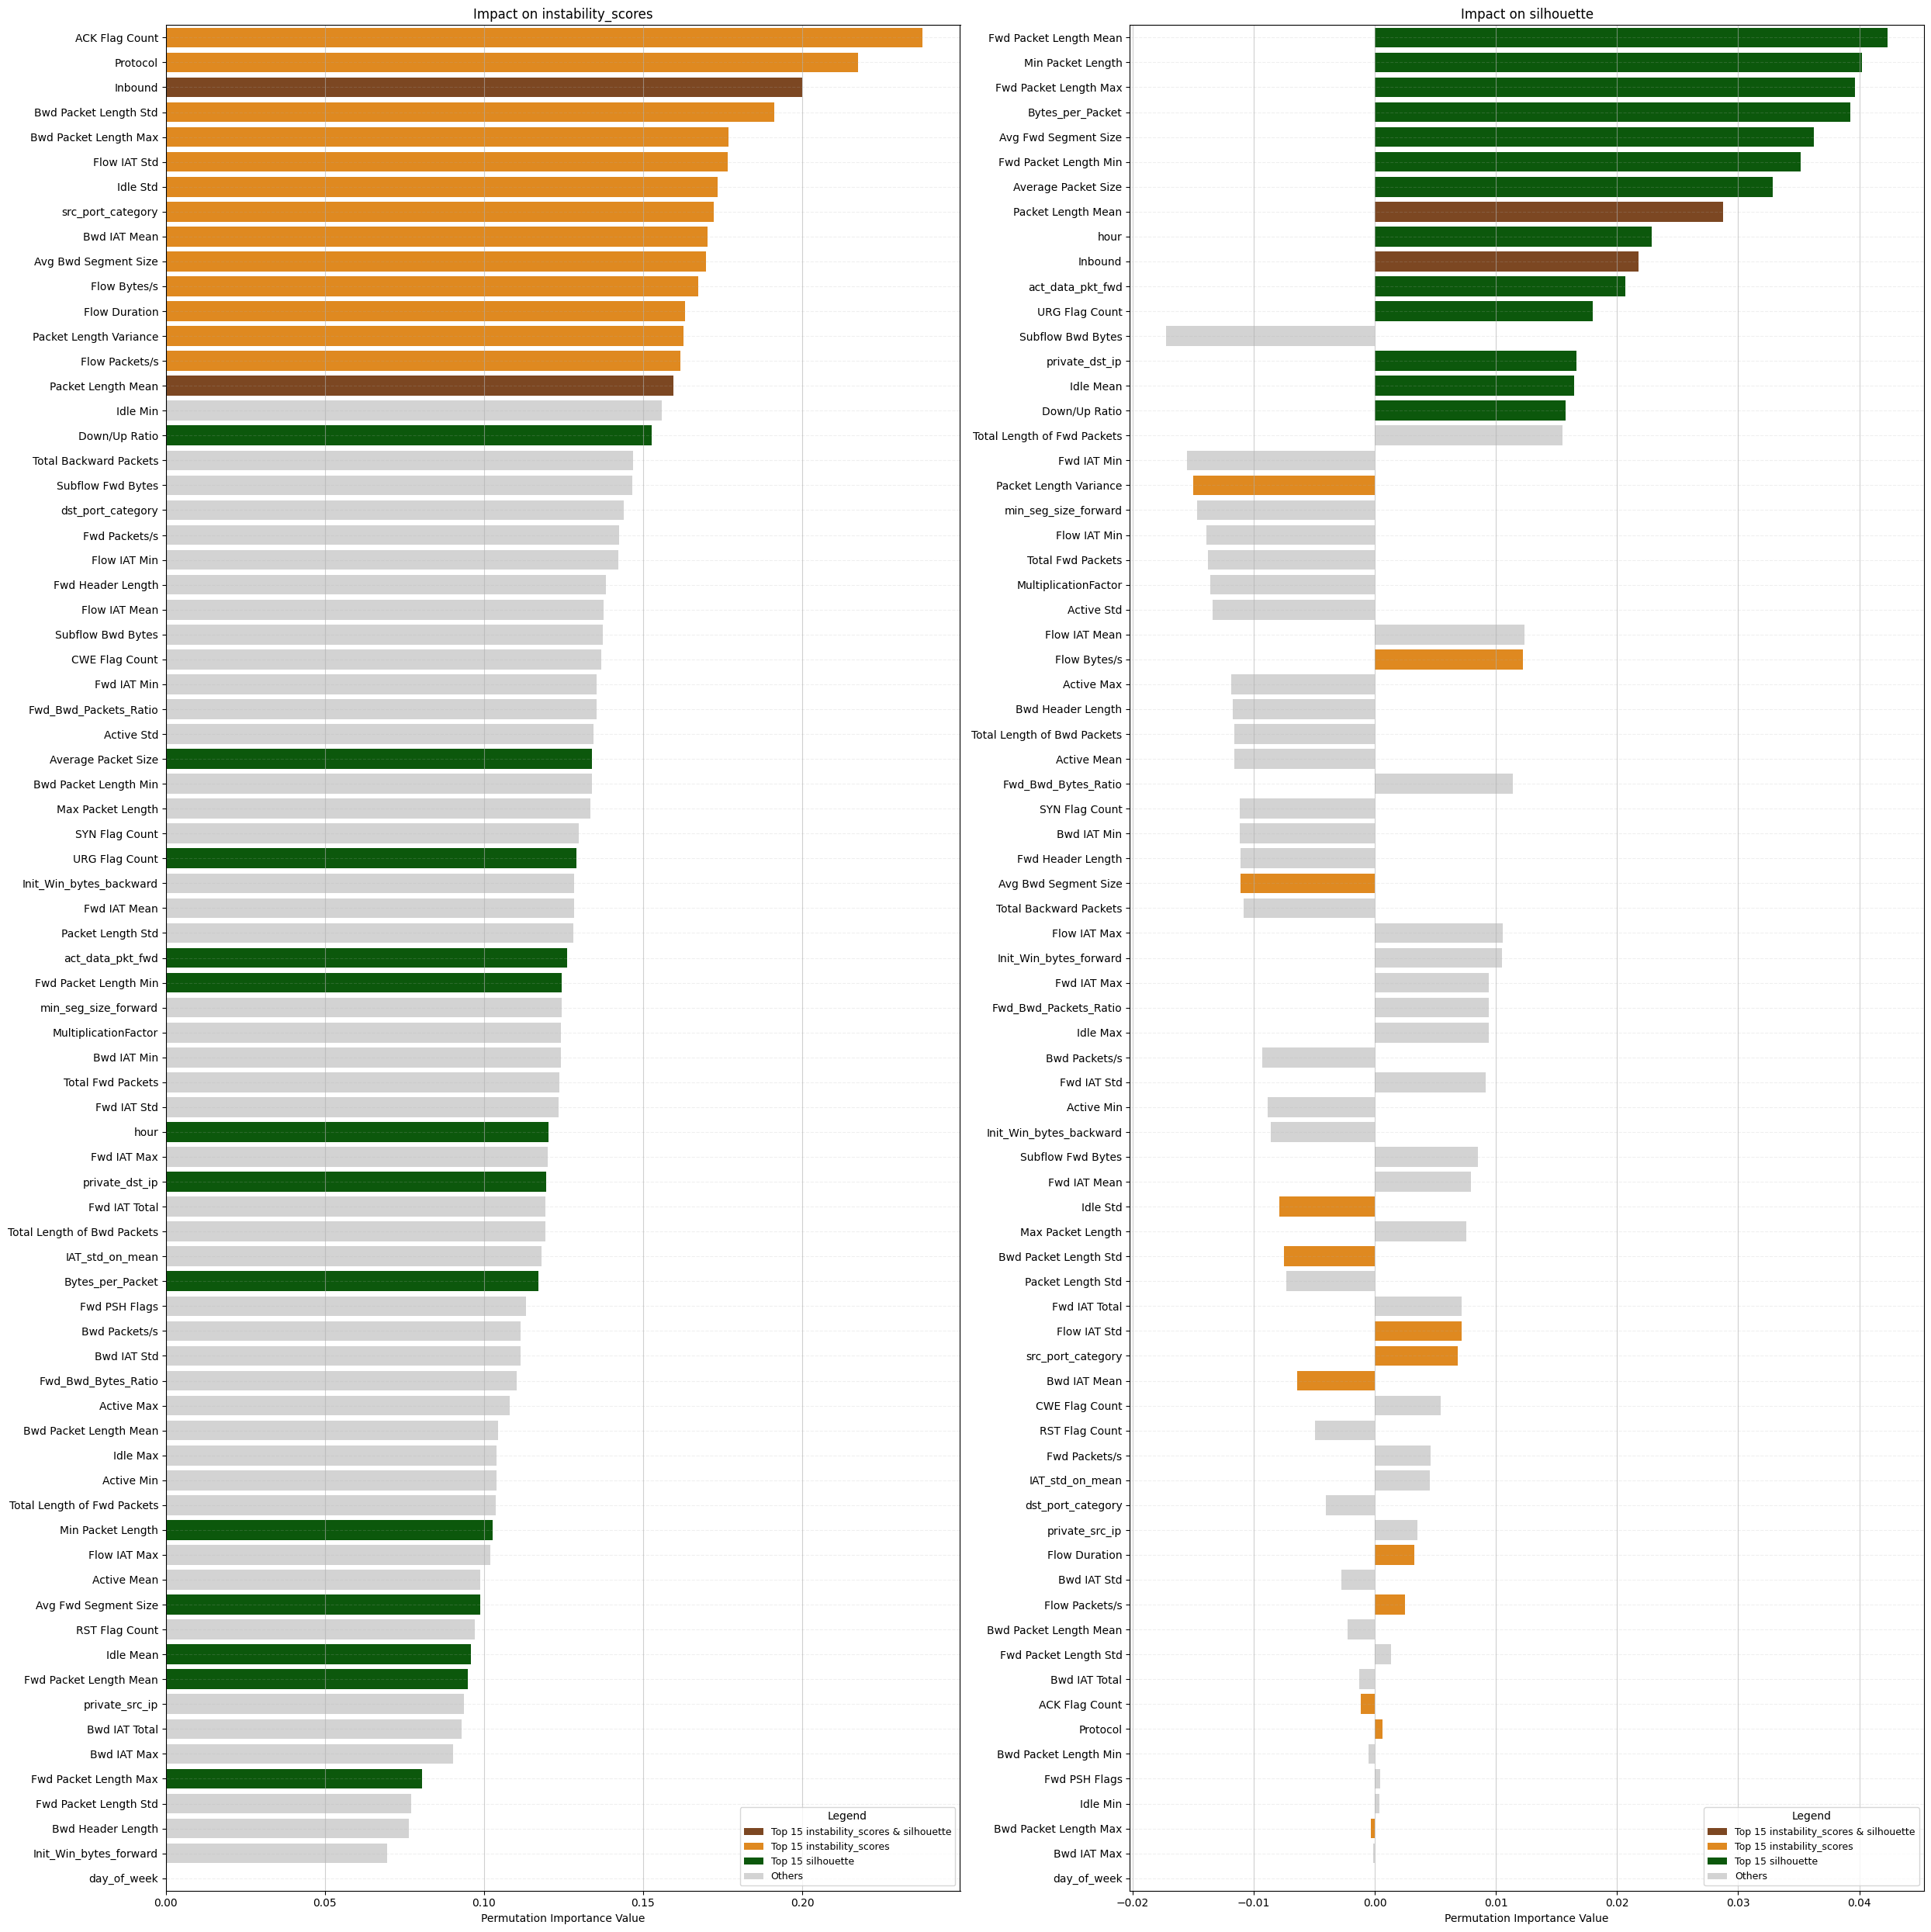

In [50]:
plot_all_importances(results,["instability_scores","silhouette"], top_n=15)

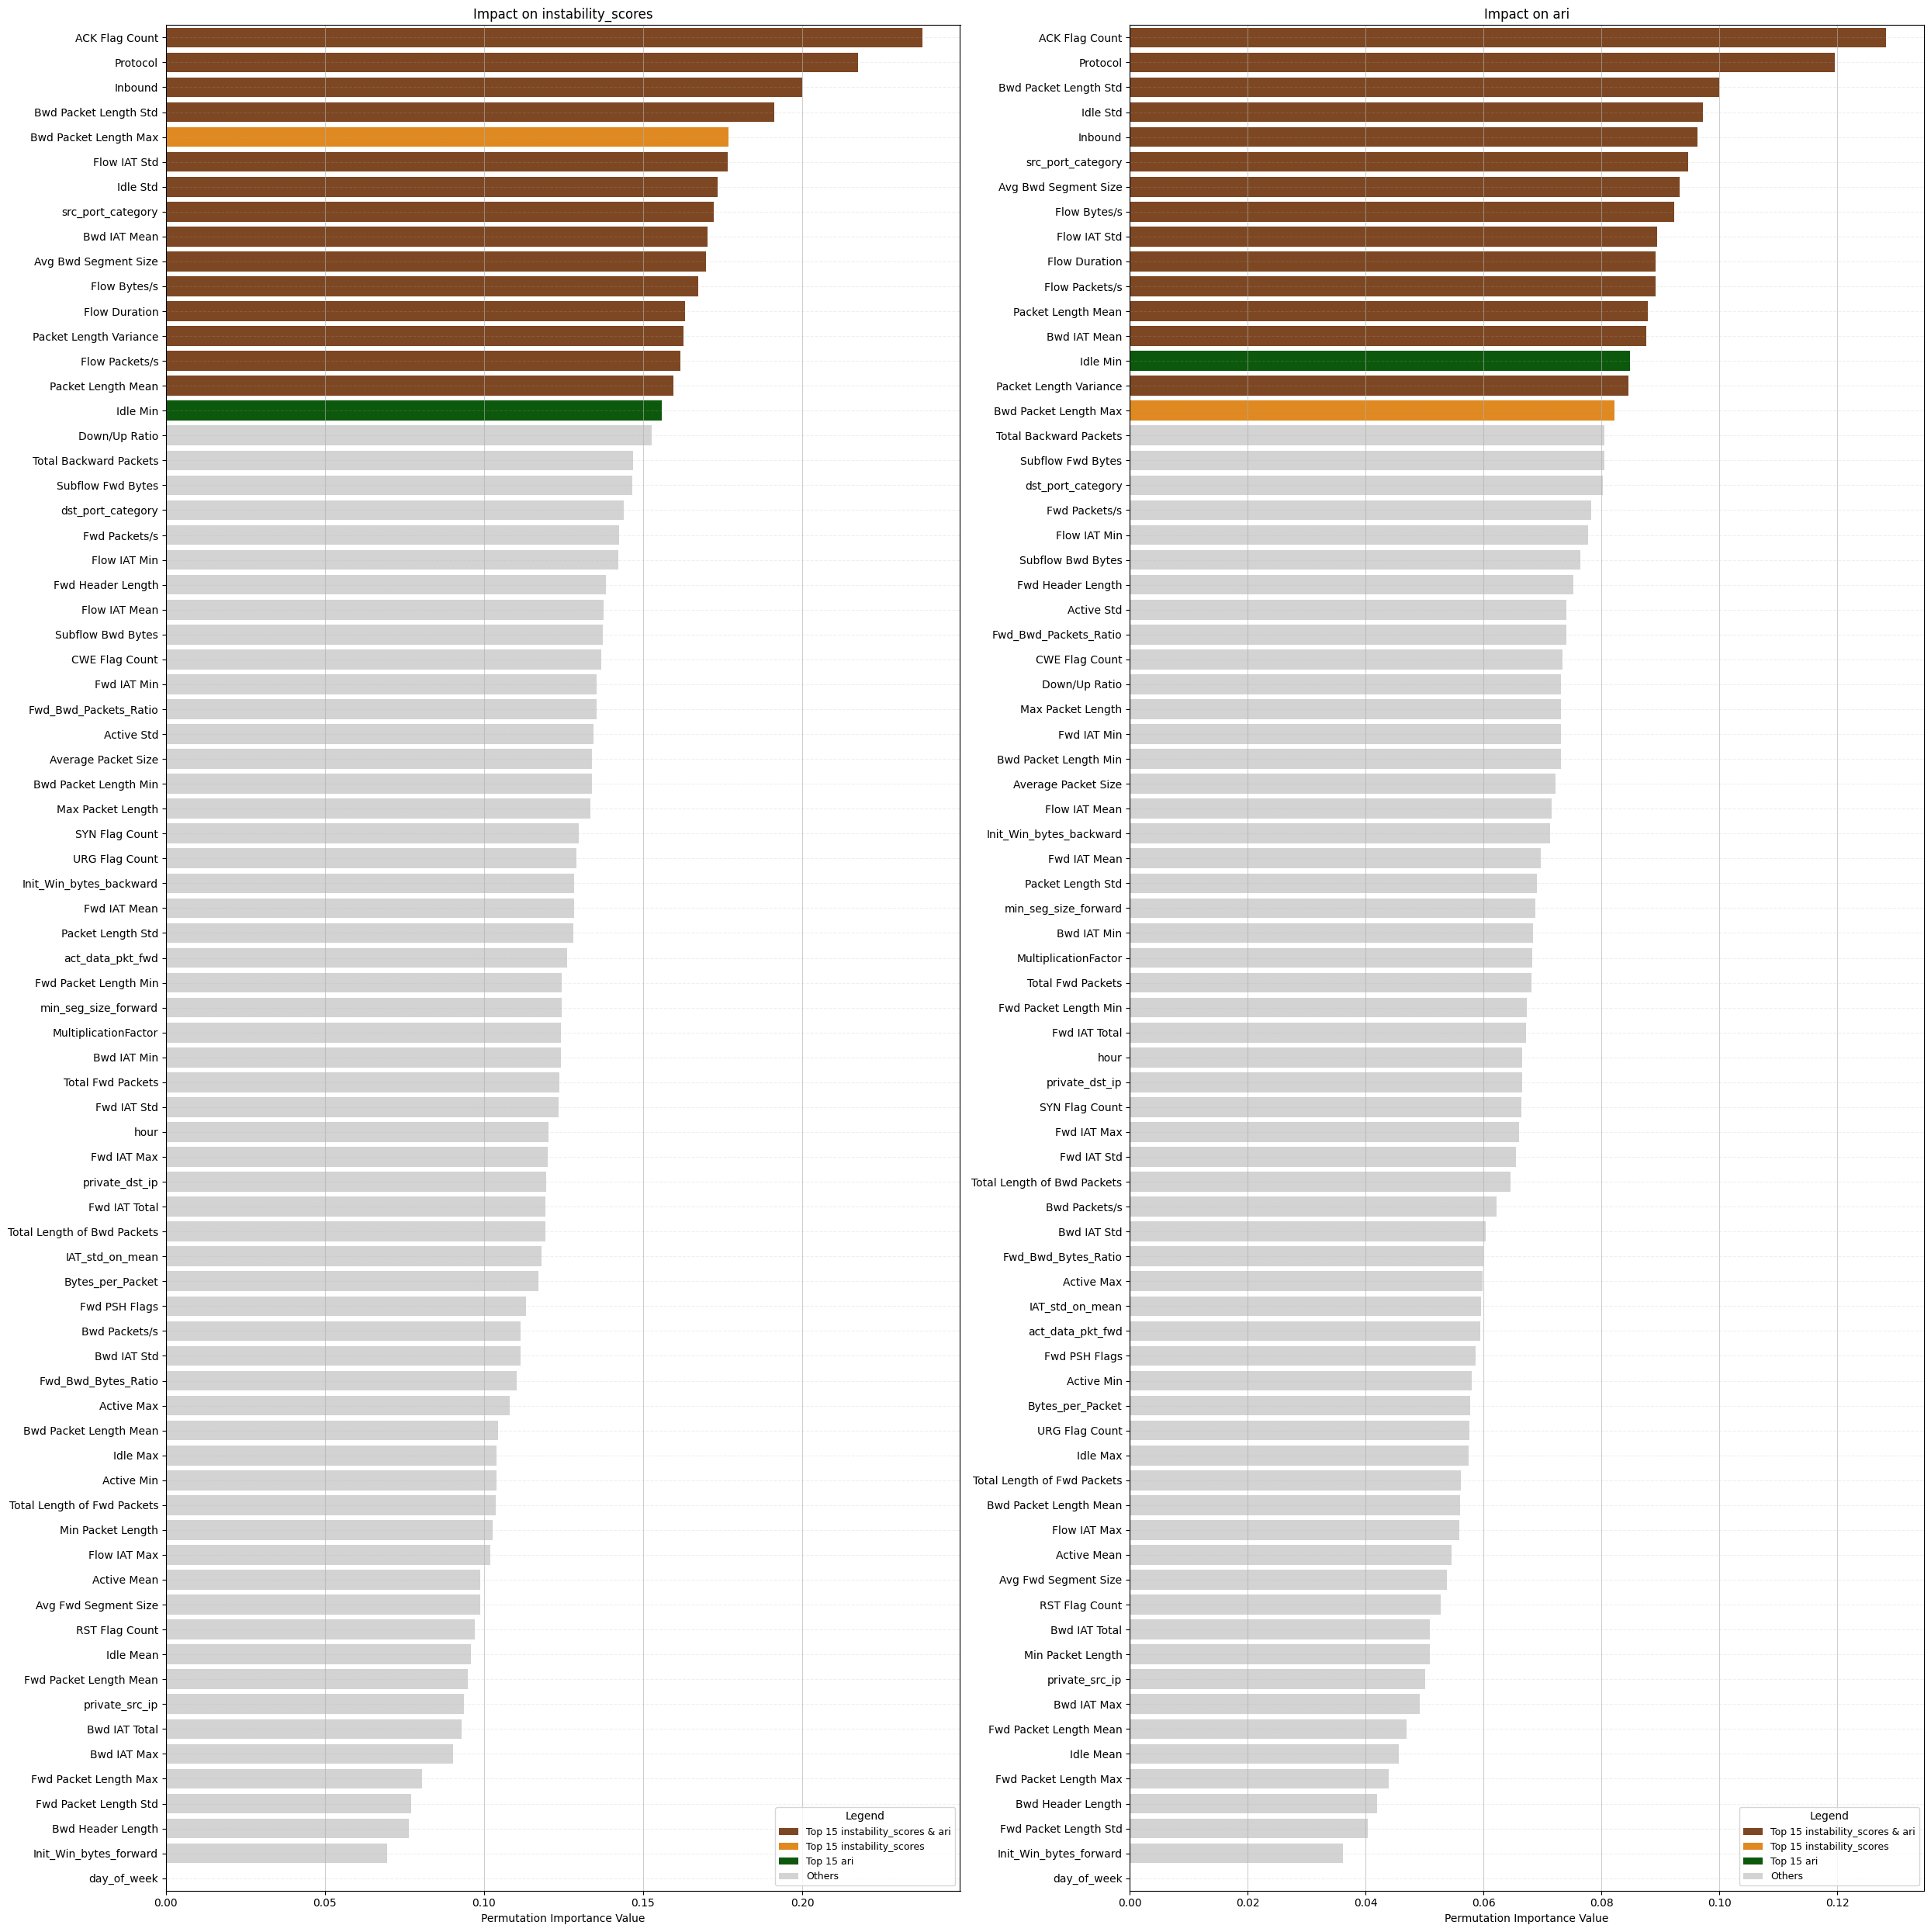

In [51]:
plot_all_importances(results,["instability_scores","ari"], top_n=15)

# Analysis of Instability Scores
The Instability Score identifies which features are foundational to the algorithm's grouping logic. A high score indicates that the feature is a primary driver of cluster formation.

- Primary Network Control Features: The ACK Flag Count, Protocol, and Inbound status emerge as the most critical features for cluster stability. The high instability values for these variables suggest they act as the primary "pivots" for the K-Means algorithm, likely separating traffic based on connection types and directional flow.

- Payload and Packet Dynamics: Features such as Bwd Packet Length Std, Bwd Packet Length Max, and Avg Bwd Segment Size show significant impact. This indicates that the variance and volume of data returning from the destination are essential for defining the "shape" of the clusters.

- Temporal and Flow Statistics: Flow IAT Std (Inter-Arrival Time) and Idle Std exhibit high importance. The algorithm relies heavily on these timing patterns to distinguish between different types of network behavior, such as persistent connections versus bursty or automated traffic.

- Throughput Metrics: Flow Bytes/s and Flow Duration are highlighted as key discriminators (indicated in green). Their removal significantly alters the resulting clusters, confirming that session density and duration are fundamental clustering criteria for this dataset.

Correlation with ARI (Adjusted Rand Index)
The comparison between Instability Scores and Impact on ARI provides a validation of the model's consistency.

- Metric Convergence: There is a strong alignment between features that provide internal stability (Instability) and those that align with the ground truth labels (ARI). Specifically, ACK Flag Count and Protocol dominate both metrics, confirming that the algorithm is capturing the most meaningful partitions in the data.

- Feature Robustness: The top 10 features identified in the Instability chart (marked in dark brown, orange, and green) remain the most influential in the ARI chart. This suggests that the structural clusters found by the algorithm are not arbitrary but are highly representative of the underlying data classes.

# 3. Attack Pattern Investigation.

### a)  Can you identify sub-attacks which belongs to the same class but have different patterns? Which feature contributes to your identification? 

Yes, the clustering clearly reveals that **sub-attacks belonging to the same DDoS class exhibit different behavioral patterns**, as they are mapped to **distinct clusters**.
1. To investigate sub-attack patterns, we analyzed the standardized mean feature values for each cluster (median values showed the same trends), focusing on features with the highest inter-cluster variance.
2. Features that showed the same values across all clusters, were excluded from the analysis, as they do not contribute to the characterization of the different sub-attack groups.
3. Clusters representing less than ~5% of the samples were excluded from the analysis, as they likely correspond to noise, outliers, or rare behaviors that do not significantly contribute to the dominant attack patterns

In [52]:
def getClassDf(ddos_class):
    df_clustered = df_pd.copy()

    df_ddos_class = df_clustered[df_clustered["label"] == ddos_class].copy().reset_index(drop=True)
    df_ddos_class = df_ddos_class.drop(columns="label")
    df_ddos_class = df_ddos_class.loc[:, df_ddos_class.nunique() > 1]

    df_ddos_class_scaled = pd.DataFrame(StandardScaler().fit_transform(df_ddos_class.drop(columns="cluster")), columns=df_ddos_class.drop(columns="cluster").columns)
    df_ddos_class_scaled['cluster'] = df_ddos_class["cluster"]
    
    return df_ddos_class, df_ddos_class_scaled

In [53]:
def plotClusterSummary(df, label):
    counts = df["cluster"].value_counts().sort_index()
    percentages = (df["cluster"].value_counts(normalize=True).sort_index() * 100)
    
    plt.figure(figsize=(14, 7))
    
    ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis', hue=counts.index, legend=False)
    
    labels = []
    for i in range(len(counts)):
        c = counts.values[i]
        p = percentages.values[i]
        testo = f'{int(c)}\n({p:.1f}%)'
        labels.append(testo)
        
    for i, container in enumerate(ax.containers):
        ax.bar_label(container, labels=[labels[i]], padding=3)

    plt.title(f"Sample Distribution by Cluster ({label})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Samples")
    plt.ylim(0, max(counts.values) * 1.15) 
    plt.grid(axis='y', linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

In [54]:
def drop_clusters(df, toDrop):
    for id in toDrop:
        df = df[df["cluster"] != id].reset_index(drop=True)
    return df

In [55]:
def plotMeanFeaturesPerCluster(df_s, mesure, ddos_class):
    if mesure == "Mean":
        df_mesure = df_s.groupby("cluster").mean().reset_index()
        sorted_features = df_s.groupby("cluster").mean().var().sort_values(ascending=False).index
    elif mesure == "Median":
        df_mesure = df_s.groupby("cluster").median().reset_index()
        sorted_features = df_s.groupby("cluster").median().var().sort_values(ascending=False).index
    else:
        print("Mesure invalid")
        return
    
    df_melted = df_mesure.melt(id_vars="cluster", var_name="Feature", value_name="Standardized Value")

    plt.figure(figsize=(10, 25)) 

    sns.barplot(data=df_melted, x="Standardized Value", y="Feature", hue="cluster", palette="viridis", order=sorted_features)

    plt.axvline(0, color='#333333', linewidth=2, label='Global Average') 
    plt.axvline(x=1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=-1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=-0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)
    plt.axvline(x=-2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)

    plt.title(f"{mesure} Values Feature per Cluster of {ddos_class}")
    plt.xlabel("Standardized Score")
    plt.ylabel("Features sorted by variance across cluster means")
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.grid(axis='y', alpha=0.6)
    plt.tight_layout()
    plt.show()

### Attack Pattern Investigation – ddos_ntp

In [56]:
df_ntp , df_ntp_scaled = getClassDf("ddos_ntp")

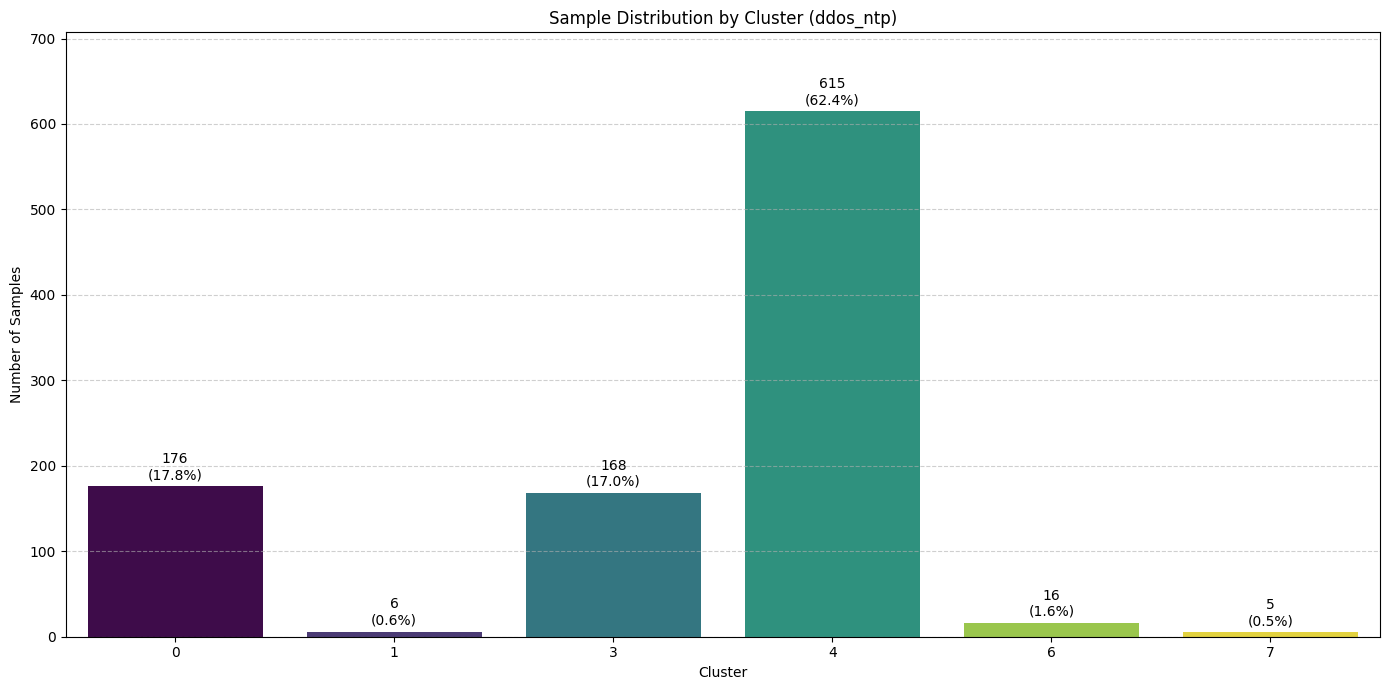

In [57]:
plotClusterSummary(df_ntp, "ddos_ntp")

In [58]:
toDrop = [1,6,7]
df_ntp = drop_clusters(df_ntp, toDrop)
df_ntp_scaled = drop_clusters(df_ntp_scaled, toDrop)

In [59]:
df_ntp.groupby("cluster").agg(["mean", "std", "median"])

Protocol                  Flow Duration                           \
             mean       std median          mean           std     median   
cluster                                                                     
0        6.000000  0.000000    6.0  5.312925e+06  1.562777e+06  5196524.0   
3        5.857143  0.917467    6.0  6.807952e+06  6.177751e+06  5447331.5   
4        6.000000  0.000000    6.0  9.043445e+04  6.057918e+05      153.0   

        Total Fwd Packets                   Total Backward Packets  ...  \
                     mean        std median                   mean  ...   
cluster                                                             ...   
0               10.409091   1.910191   12.0               7.789773  ...   
3               12.172619  11.217500    5.0              12.321429  ...   
4                1.113821   0.567916    1.0               1.634146  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                          \
                       median                mean           std    median   
cluster                                                                     
0                    1.333333        4.614217e-01  8.918043e-02  0.427739   
3                    1.041667        8.299799e-01  2.311508e-01  1.000000   
4                    0.500000        1.213821e+13  1.292197e+14  1.000000   

        src_port_category                  dst_port_category                   
                     mean       std median              mean       std median  
cluster                                                                        
0                1.511364  0.501297    2.0          0.000000  0.000000    0.0  
3                1.339286  0.522893    1.0          0.226190  0.473266    0.0  
4                0.723577  0.808151    0.0          0.731707  0.807872    1.0  

[3 rows x 210 columns]

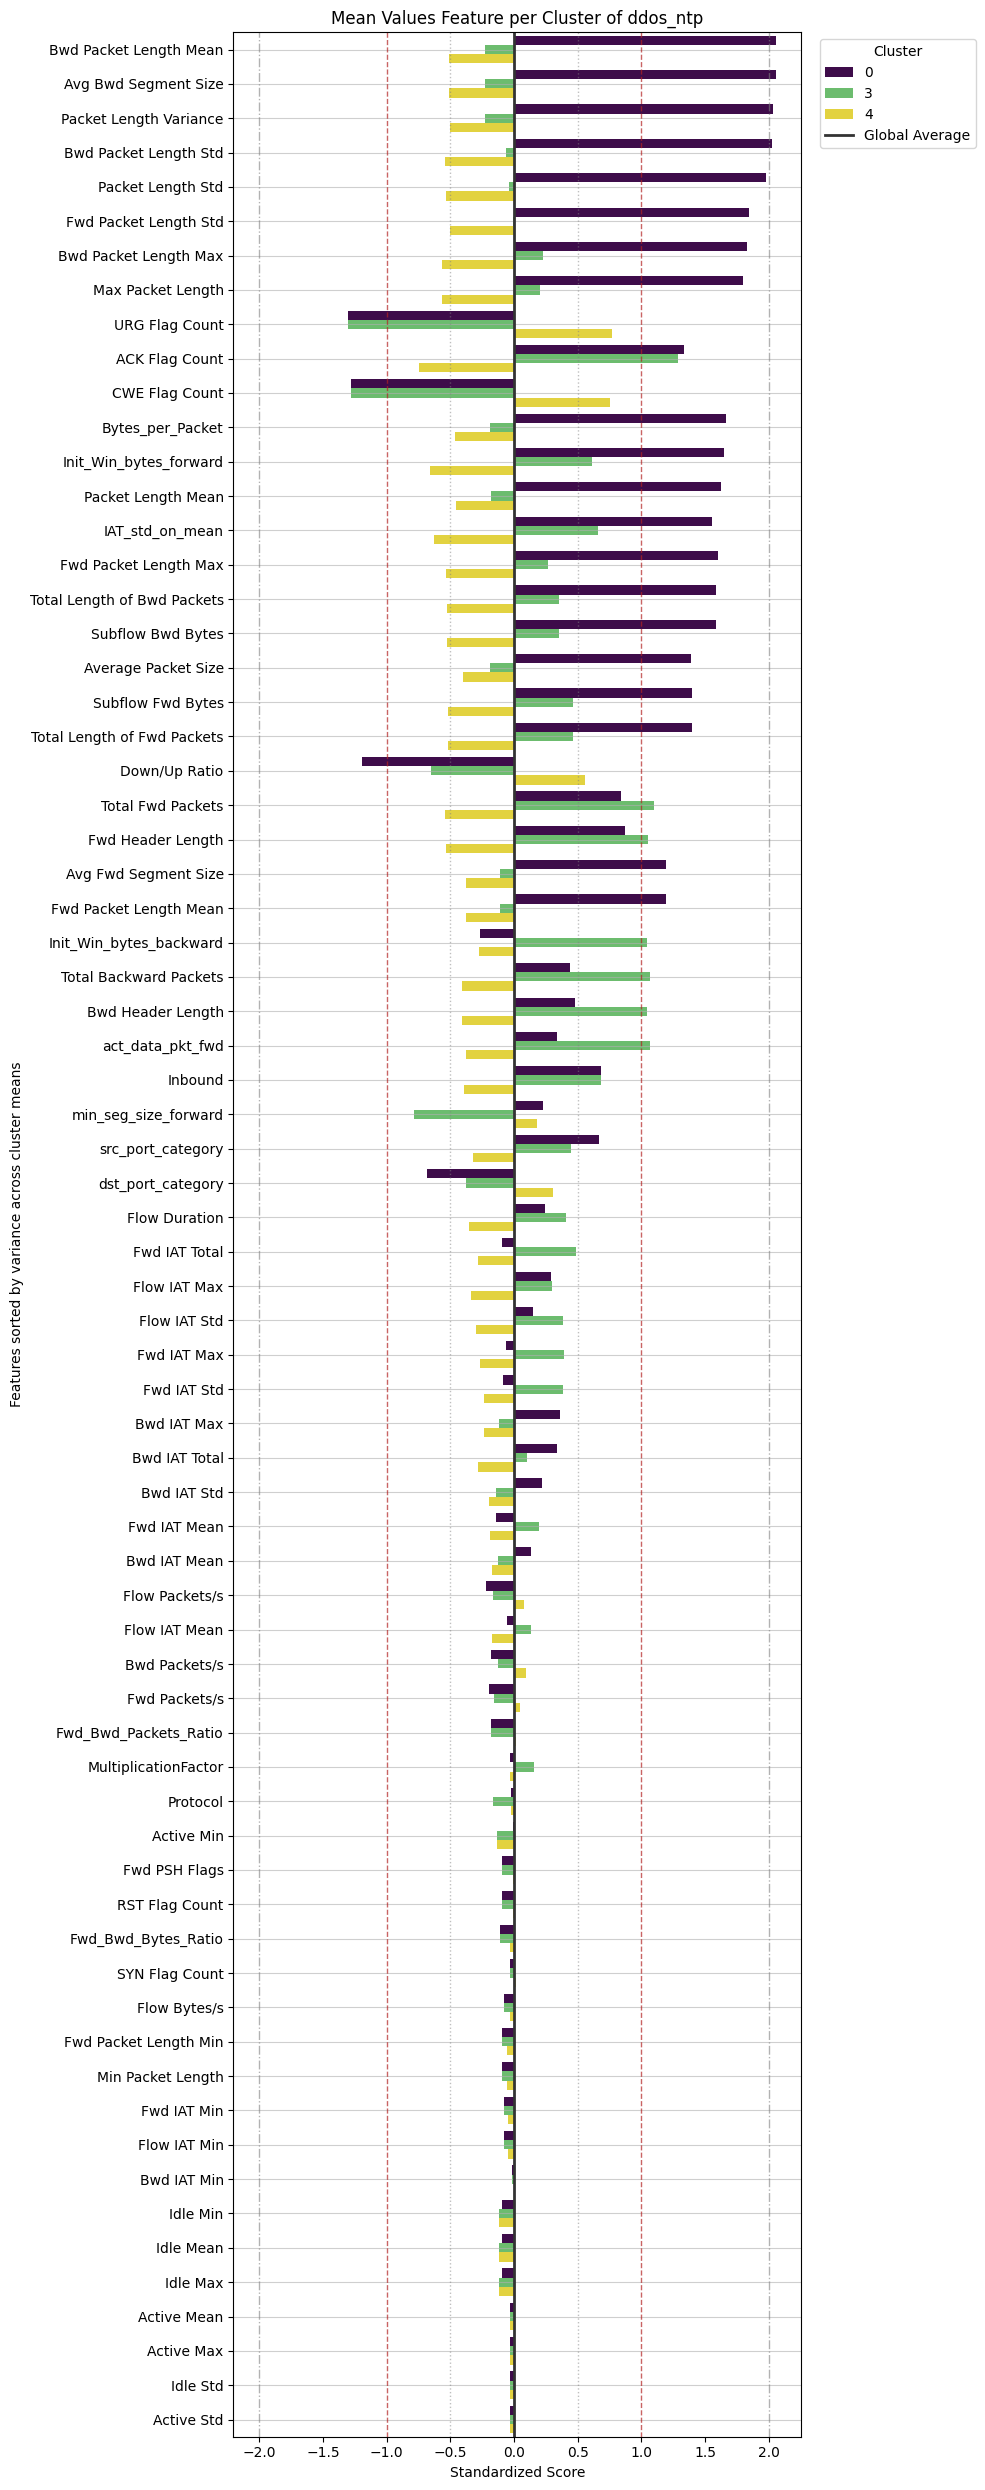

In [60]:
plotMeanFeaturesPerCluster(df_ntp_scaled, "Mean", "ddos_ntp")

### Attack Pattern Investigation – ddos_syn

In [61]:
df_syn , df_syn_scaled = getClassDf("ddos_syn")

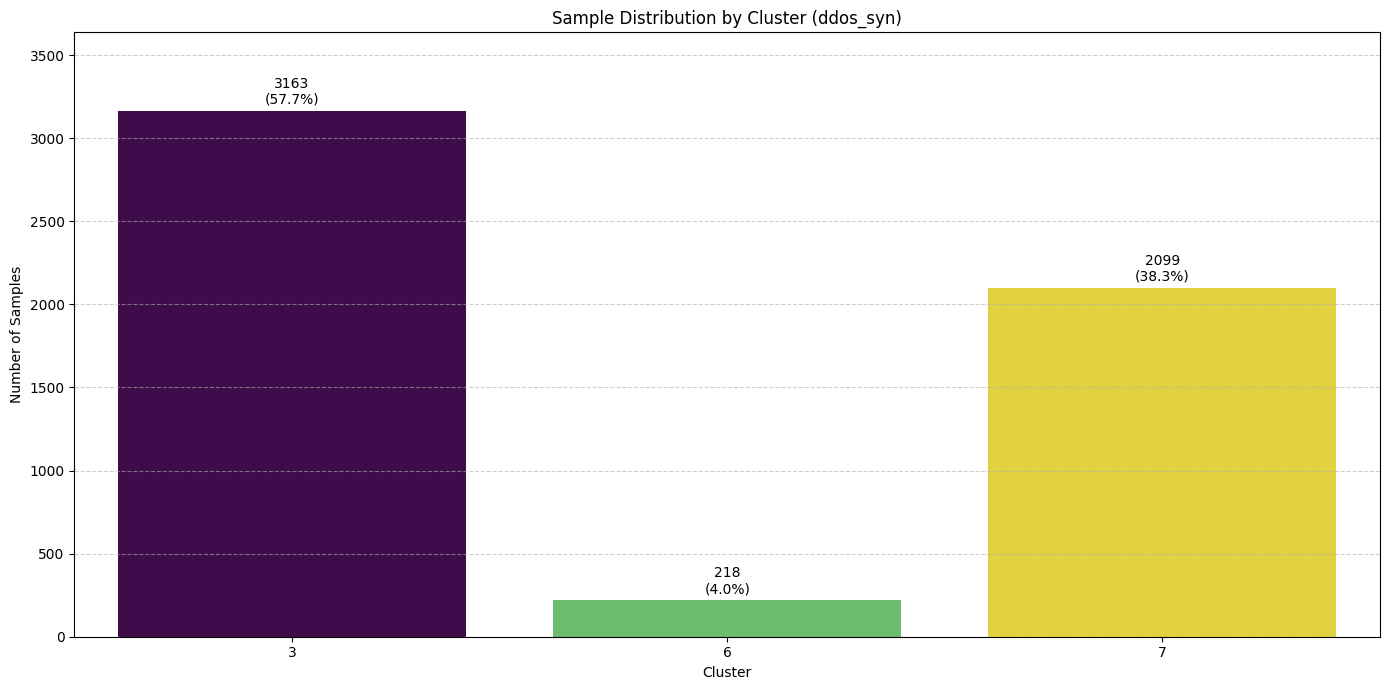

In [62]:
plotClusterSummary(df_syn,"ddos_syn")

In [63]:
df_syn.groupby("cluster").agg(["mean", "std", "median"])

Protocol                  Flow Duration                             \
             mean       std median          mean           std       median   
cluster                                                                       
3        5.998103  0.106685    6.0  4.171466e+04  2.125261e+06          1.0   
6        6.000000  0.000000    6.0  1.120016e+08  5.886453e+06  112762340.0   
7        6.000000  0.000000    6.0  1.094126e+08  8.534442e+06  111099837.0   

        Total Fwd Packets                   Total Backward Packets  ...  \
                     mean        std median                   mean  ...   
cluster                                                             ...   
3                3.387291  77.488520    2.0               0.308568  ...   
6               16.275229   2.319509   16.0               4.733945  ...   
7               14.607432   2.561589   14.0               1.261553  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                       \
                       median                mean           std median   
cluster                                                                  
3                2.000000e+12        1.000000e+00  0.000000e+00    1.0   
6                3.500000e+00        1.000000e+00  0.000000e+00    1.0   
7                1.000000e+01        2.667937e+10  1.222311e+12    1.0   

        src_port_category                  dst_port_category                   
                     mean       std median              mean       std median  
cluster                                                                        
3                1.949099  0.290480    2.0          1.245337  0.470381    1.0  
6                1.284404  0.500539    1.0          1.238532  0.478074    1.0  
7                1.299667  0.480561    1.0          1.232015  0.446365    1.0  

[3 rows x 168 columns]

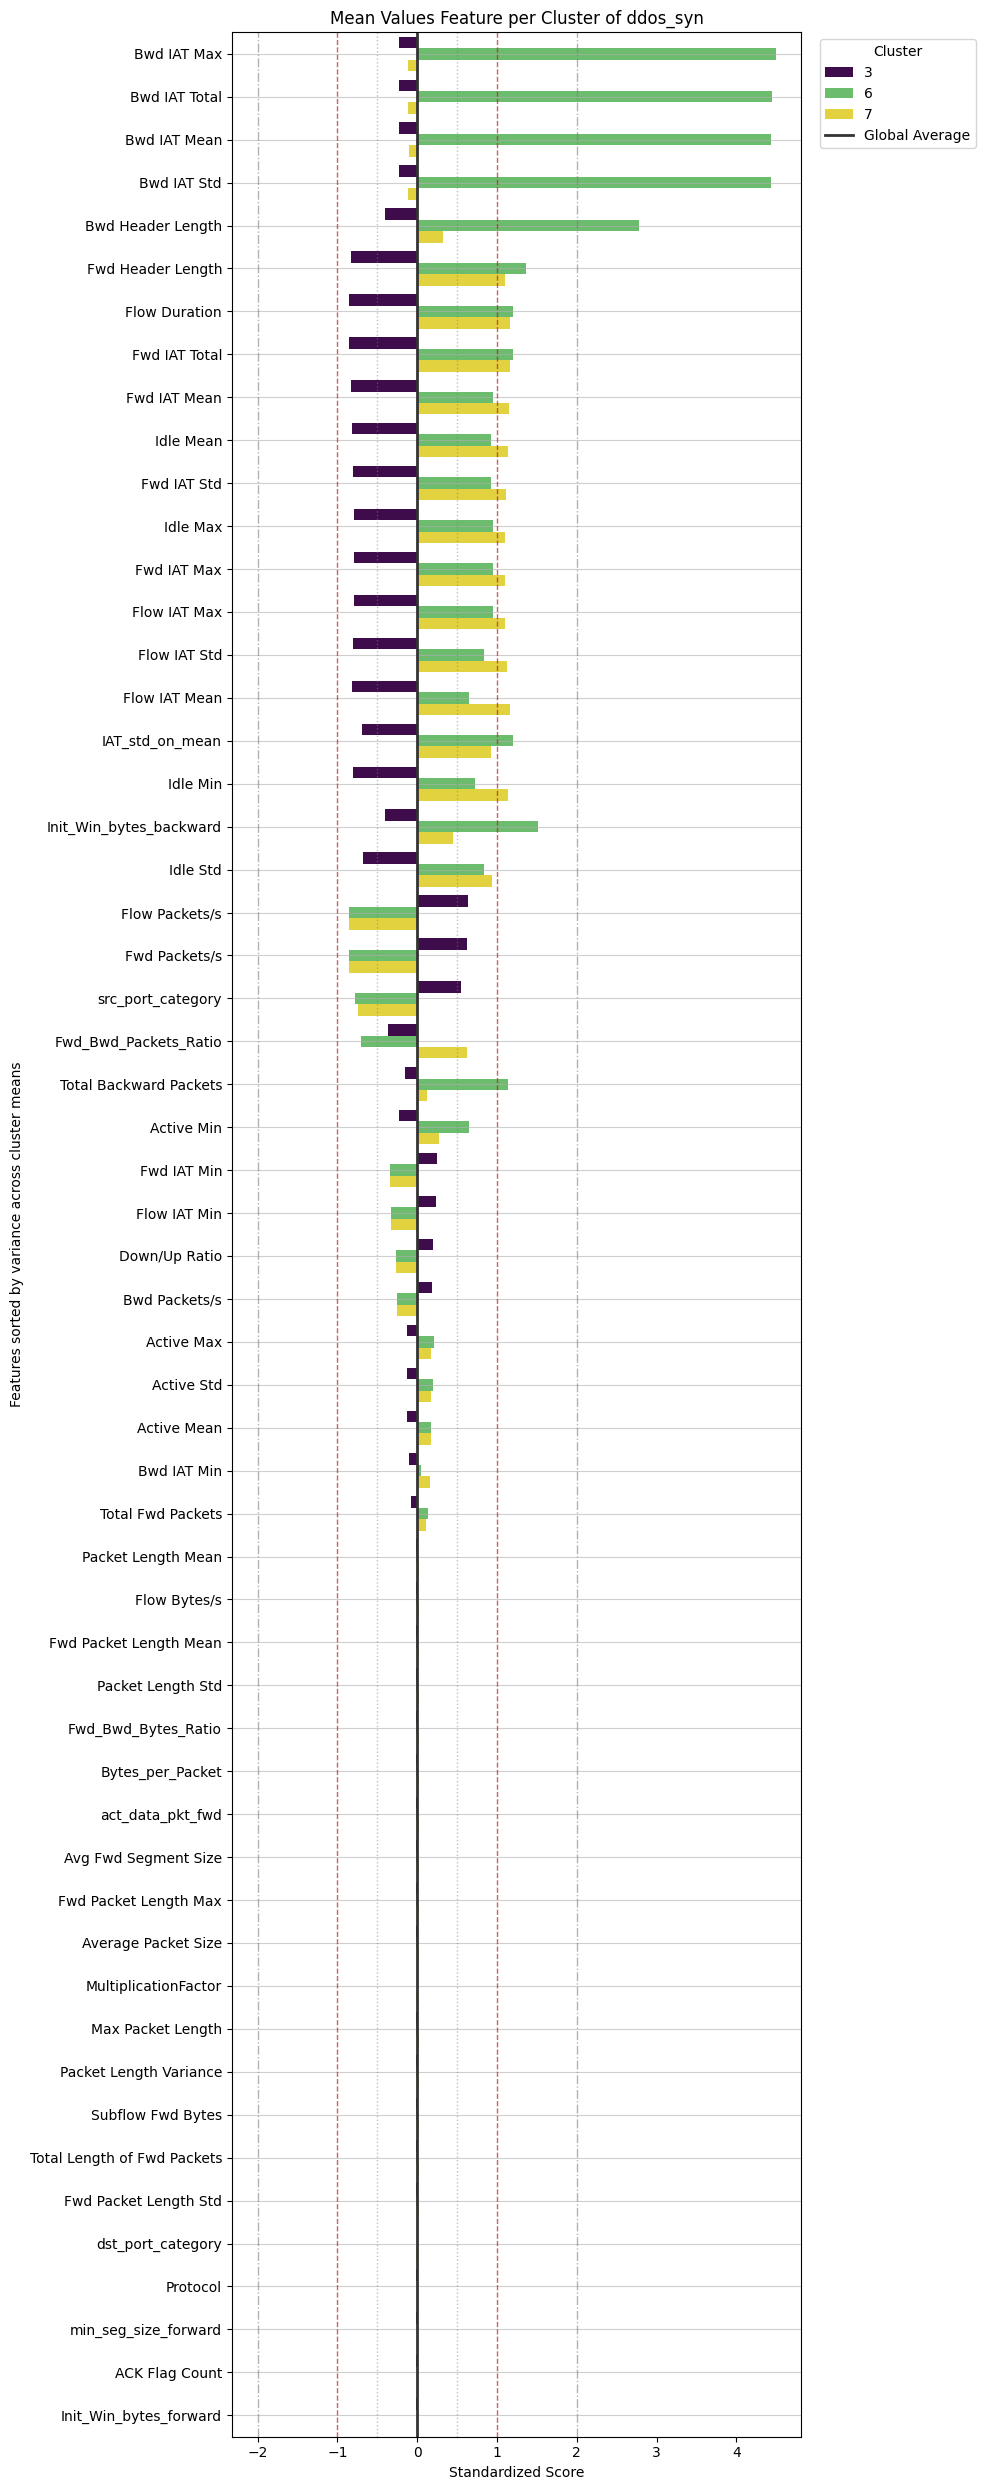

In [64]:
plotMeanFeaturesPerCluster(df_syn_scaled, "Mean", "ddos_syn")

### Attack Pattern Investigation – ddos_dns

In [65]:
df_dns , df_dns_scaled = getClassDf("ddos_dns")

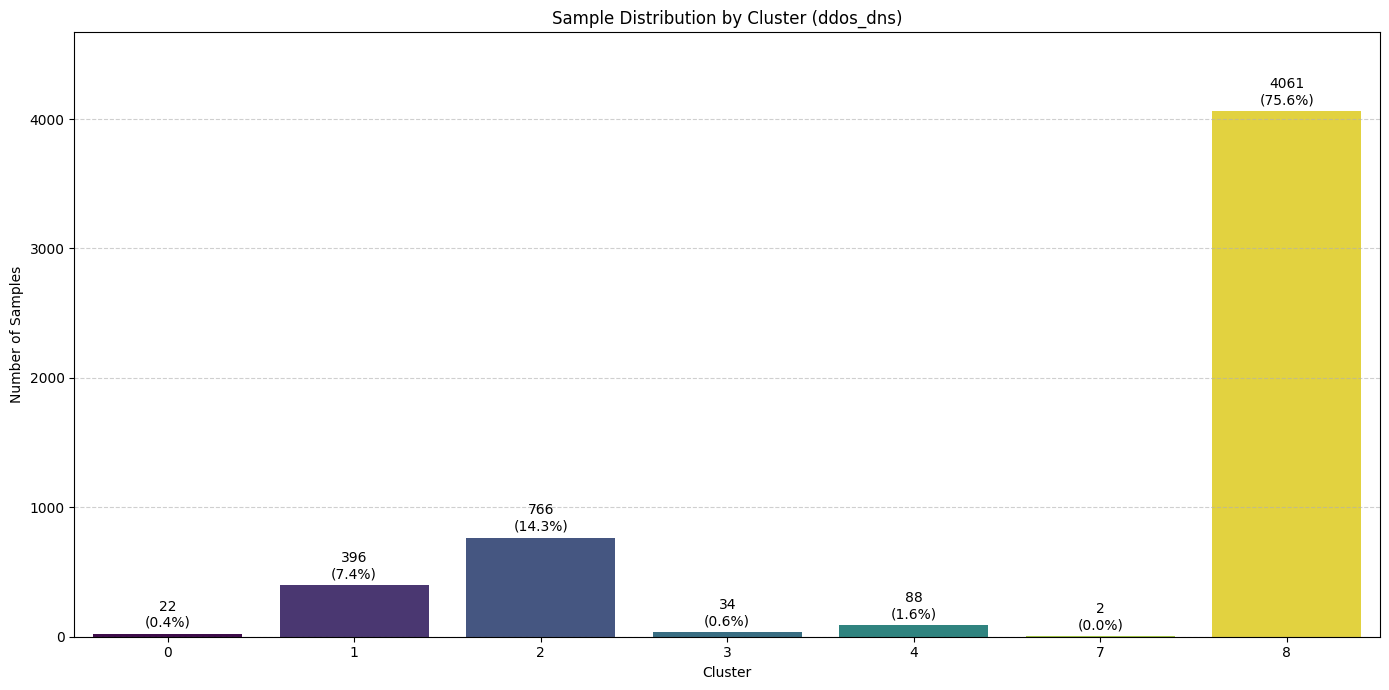

In [66]:
plotClusterSummary(df_dns, "ddos_dns")

In [67]:
toDrop = [0,3,4,7]
df_dns = drop_clusters(df_dns, toDrop)
df_dns_scaled = drop_clusters(df_dns_scaled, toDrop)

In [68]:
df_dns.groupby("cluster").agg(["mean", "std", "median"])

Protocol                   Flow Duration                         \
              mean       std median           mean           std   median   
cluster                                                                     
1        16.972222  0.552771   17.0    3962.247475  1.206069e+04      2.0   
2        17.000000  0.000000   17.0     889.041775  3.769648e+03      2.0   
8        17.000000  0.000000   17.0  130111.720758  1.109255e+06  30928.0   

        Total Fwd Packets                   Total Backward Packets  ...  \
                     mean        std median                   mean  ...   
cluster                                                             ...   
1                7.340909  19.690065    2.0           1.000000e-12  ...   
2                2.248042   0.659641    2.0           1.000000e-12  ...   
8              192.652056  22.622689  200.0           1.000000e-12  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                              \
                       median                mean           std        median   
cluster                                                                         
1                2.000000e+12        3.256631e+15  8.665975e+15  8.800000e+14   
2                2.000000e+12        3.255948e+15  9.780271e+14  2.944000e+15   
8                2.000000e+14        8.467368e+16  1.006473e+16  8.800000e+16   

        src_port_category                  dst_port_category                   
                     mean       std median              mean       std median  
cluster                                                                        
1                0.356061  0.751025    0.0          1.277778  0.465097    1.0  
2                0.775457  0.956149    0.0          1.232376  0.422623    1.0  
8                0.000000  0.000000    0.0          1.247968  0.457907    1.0  

[3 rows x 210 columns]

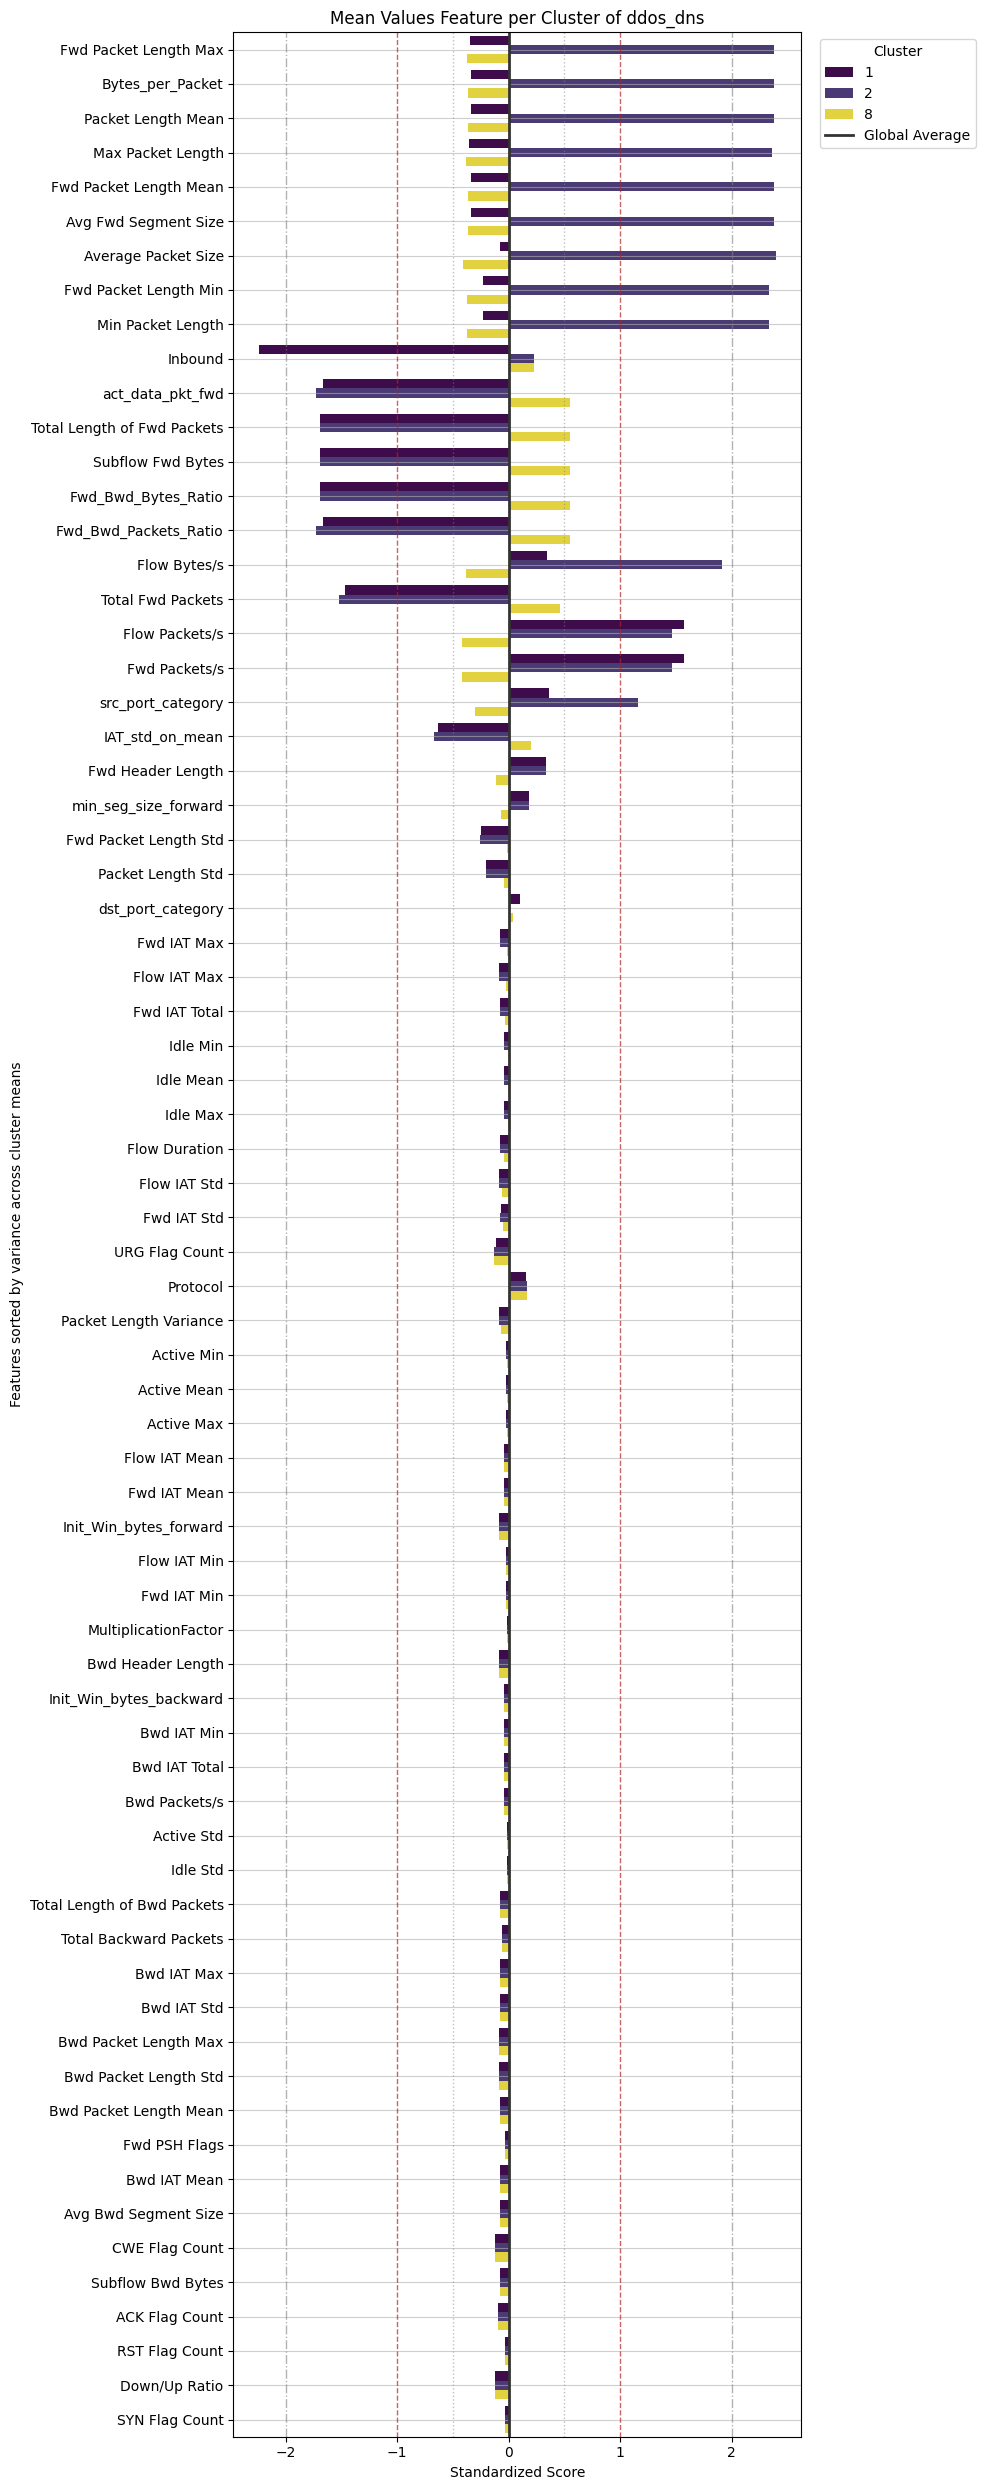

In [69]:
plotMeanFeaturesPerCluster(df_dns_scaled, "Mean", "ddos_dns")

### Attack Pattern Investigation – ddos_netbios

In [70]:
df_netbios , df_netbios_scaled = getClassDf("ddos_netbios")

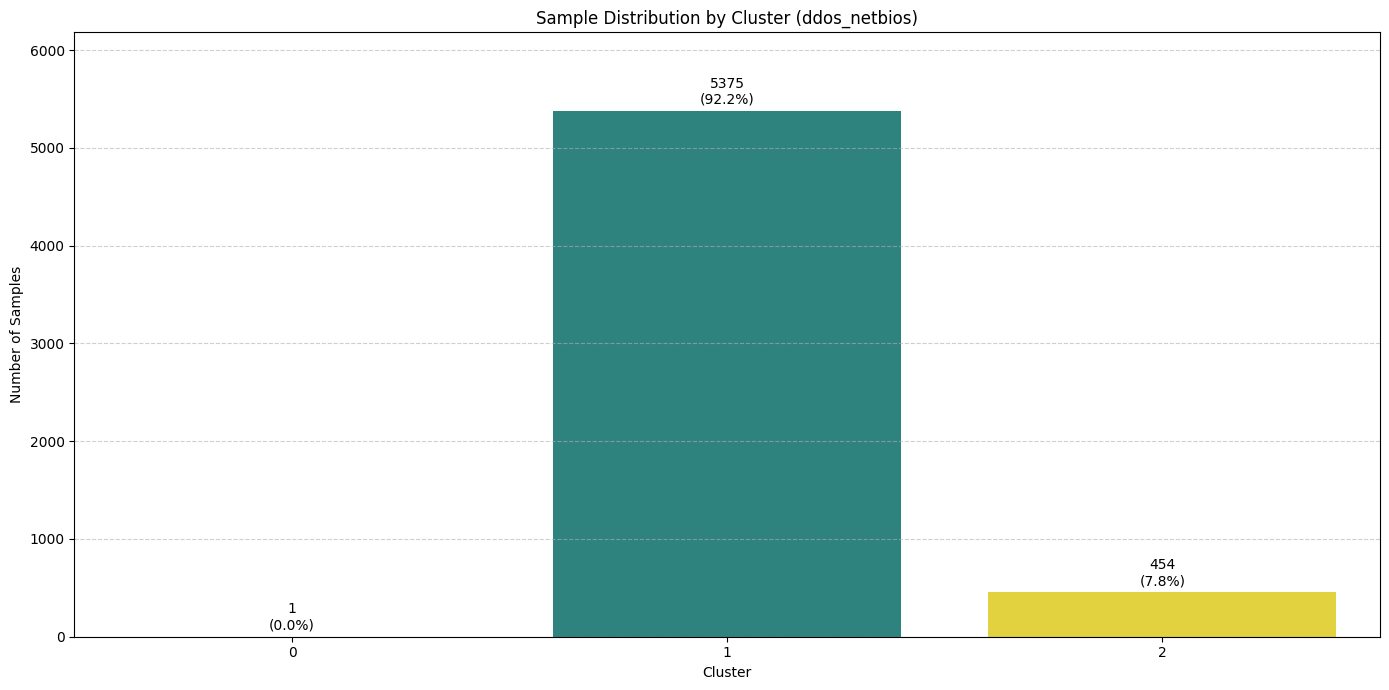

In [71]:
plotClusterSummary(df_netbios, "ddos_netbios")

In [72]:
toDrop = [0]
df_netbios = drop_clusters(df_netbios, toDrop)
df_netbios_scaled = drop_clusters(df_netbios_scaled, toDrop)

In [73]:
df_netbios.groupby("cluster").agg(["mean", "std", "median"])

Protocol             Flow Duration                        \
            mean  std median          mean            std median   
cluster                                                            
1           17.0  0.0   17.0    3489.08186  133534.820747    1.0   
2           17.0  0.0   17.0       1.57489       3.962003    1.0   

        Total Fwd Packets                  Total Backward Packets  ...  \
                     mean       std median                   mean  ...   
cluster                                                            ...   
1                2.001488  0.054544    2.0           1.000000e-12  ...   
2                2.000000  0.000000    2.0           1.000000e-12  ...   

        Fwd_Bwd_Packets_Ratio Fwd_Bwd_Bytes_Ratio                              \
                       median                mean           std        median   
cluster                                                                         
1                2.000000e+12        1.028586e+15  2.196346e+14  9.440000e+14   
2                2.000000e+12        2.435872e+15  4.194165e+14  2.558000e+15   

        src_port_category                  dst_port_category                   
                     mean       std median              mean       std median  
cluster                                                                        
1                1.161674  0.368186    1.0          1.230512  0.456397    1.0  
2                1.138767  0.346084    1.0          1.202643  0.453967    1.0  

[2 rows x 153 columns]

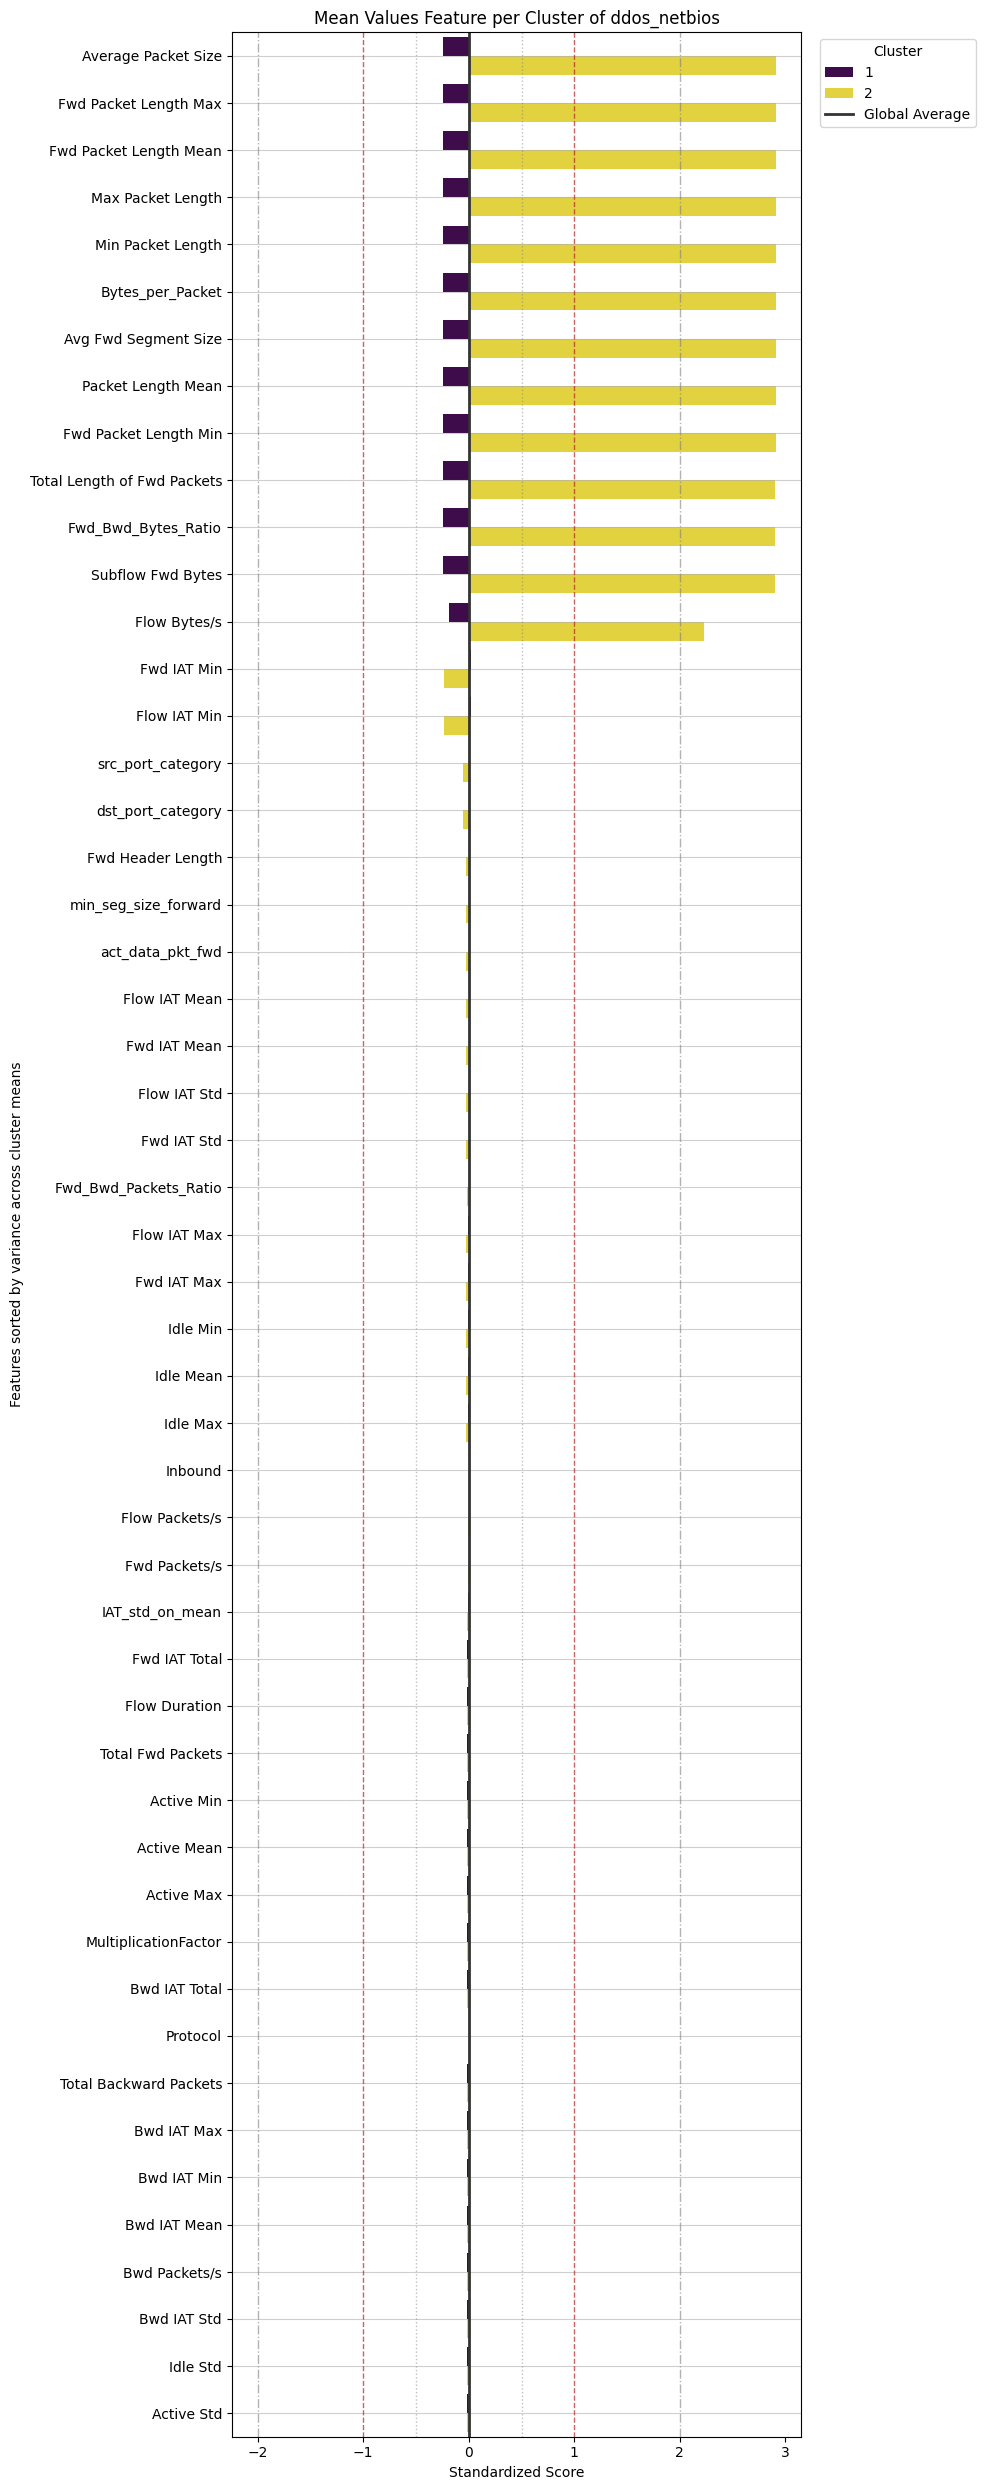

In [74]:
plotMeanFeaturesPerCluster(df_netbios_scaled, "Mean", "ddos_netbios")

### b)  Which attacks are more similar? According to which feature? Can you explain why according to their definition or attack manner? 

Yes, the clustering clearly reveals that **attacks belonging to different DDoS class show same behavioral patterns**, as they are mapped to **same clusters**.

1. To identify which attacks exhibit the most similar behaviors, we examined the standardized feature distributions of different attack labels co-existing within Clusters, ranking features according to their inter-label variance within the cluster.
2. Features that showed the same values across all clusters, were excluded from the analysis, as they do not contribute to the characterization of the different sub-attack groups.
3. Labels representing less than ~5% of the samples were excluded from the analysis, as they likely correspond to noise, outliers, or rare behaviors that do not significantly contribute to the dominant attack patterns

In [75]:
def getClusterDf(cluster_id):
    df_clustered = df_pd.copy()

    df_cluster = df_clustered[df_clustered["cluster"] == cluster_id].copy().reset_index(drop=True)
    df_cluster = df_cluster.drop(columns="cluster")
    df_cluster = df_cluster.loc[:, df_cluster.nunique() > 1]

    df_cluster_scaled = pd.DataFrame(StandardScaler().fit_transform(df_cluster.drop(columns="label")), columns=df_cluster.drop(columns="label").columns)
    df_cluster_scaled['label'] = df_cluster["label"]
    
    return df_cluster, df_cluster_scaled

In [76]:
def plotLabelSummary(df, cluster):
    counts = df["label"].value_counts().sort_index()
    percentages = (df["label"].value_counts(normalize=True).sort_index() * 100)

    plt.figure(figsize=(14, 7))

    ax = sns.barplot(x=counts.index, y=counts.values, palette='viridis', hue=counts.index, legend=False)

    labels = []
    for i in range(len(counts)):
        c = counts.values[i]
        p = percentages.values[i]
        testo = f'{int(c)}\n({p:.1f}%)'
        labels.append(testo)
        
    for i, container in enumerate(ax.containers):
        ax.bar_label(container, labels=[labels[i]], padding=3)

    plt.title(f"Sample Distribution by Label (cluster {cluster})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Samples")
    plt.ylim(0, max(counts.values) * 1.15) 
    plt.grid(axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

In [77]:
def drop_Labels(df, toDrop):
    for id in toDrop:
        df = df[df["label"] != id].reset_index(drop=True)
    return df

In [78]:
def plotMeanFeaturesPerLabel(df_s, mesure, cluster_id):
    if mesure == "Mean":
        df_mesure = df_s.groupby("label").mean().reset_index()
        sorted_features = df_s.groupby("label").mean().var().sort_values(ascending=False).index
    elif mesure == "Median":
        df_mesure = df_s.groupby("label").median().reset_index()
        sorted_features = df_s.groupby("label").median().var().sort_values(ascending=False).index
    else:
        print("Mesure invalid")
        return
    
    df_melted = df_mesure.melt(id_vars="label", var_name="Feature", value_name="Standardized Value")

    plt.figure(figsize=(15, 25)) 

    sns.barplot(data=df_melted, x="Standardized Value", y="Feature", hue="label", palette="viridis", order=sorted_features)

    plt.axvline(0, color='#333333', linewidth=2, label='Global Average') 
    plt.axvline(x=1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=-1, color='firebrick', linestyle='--', linewidth=1, alpha=0.7)
    plt.axvline(x=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=-0.5, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    plt.axvline(x=2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)
    plt.axvline(x=-2, color='gray', linestyle='-.', linewidth=1, alpha=0.6)

    plt.title(f"{mesure} Values Feature per Label of cluster {cluster_id}")
    plt.xlabel("Standardized Score")
    plt.ylabel("Features")
    plt.legend(title="Label", bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.grid(axis='y', alpha=0.6)
    plt.tight_layout()
    plt.show()

### Attack Pattern Investigation – cluster 1

In [79]:
df_cluster_1 , df_cluster_1_scaled = getClusterDf(1)

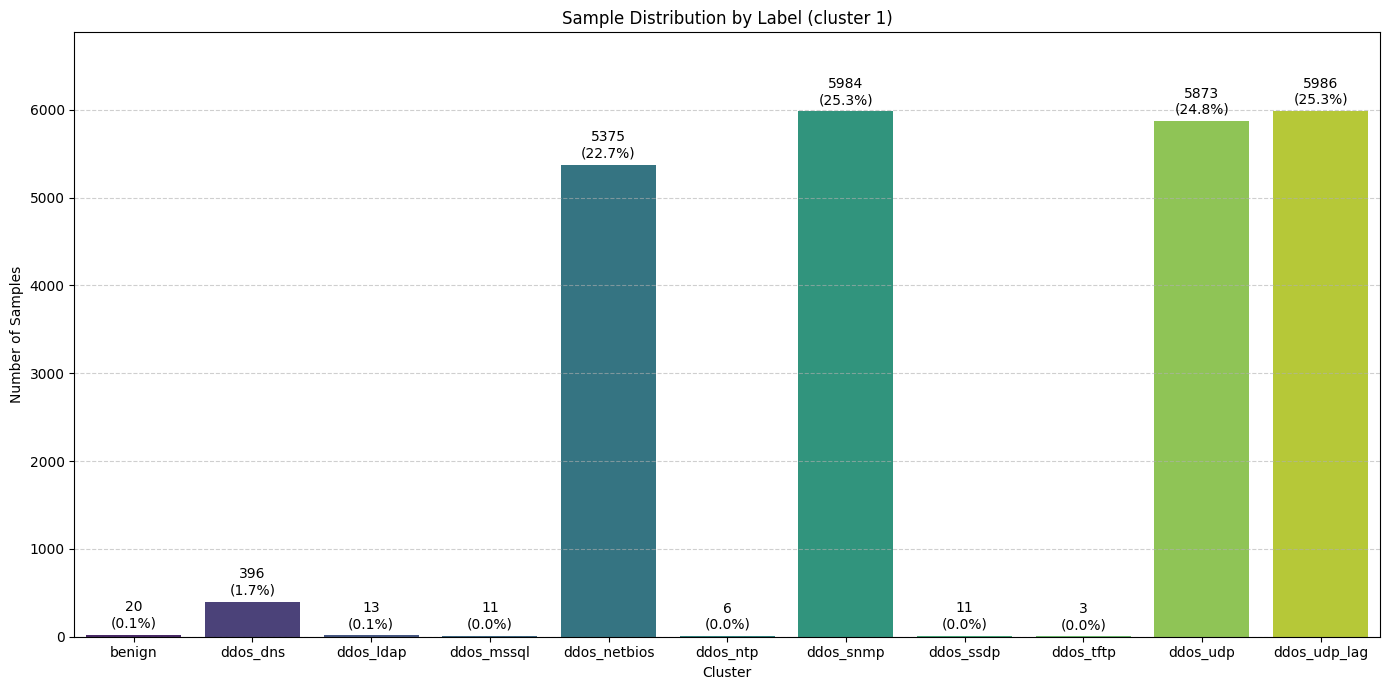

In [80]:
plotLabelSummary(df_cluster_1,1)

In [81]:
toDrop = ["benign","ddos_ldap", "ddos_mssql", "ddos_ntp", "ddos_ssdp", "ddos_tftp"]
df_cluster_1 = drop_Labels(df_cluster_1, toDrop)
df_cluster_1_scaled = drop_Labels(df_cluster_1_scaled, toDrop)

In [82]:
df_cluster_1.groupby("label").agg(["mean", "std", "median"])

Protocol                  Flow Duration                 \
                   mean       std median          mean            std   
label                                                                   
ddos_dns      16.972222  0.552771   17.0   3962.247475   12060.692421   
ddos_netbios  17.000000  0.000000   17.0   3489.081860  133534.820747   
ddos_snmp     17.000000  0.000000   17.0      8.033757      25.660550   
ddos_udp      17.000000  0.000000   17.0  92765.023327  150486.852164   
ddos_udp_lag  17.000000  0.000000   17.0  84985.861844  141098.687429   

                       Total Fwd Packets                    \
                median              mean        std median   
label                                                        
ddos_dns           2.0          7.340909  19.690065    2.0   
ddos_netbios       1.0          2.001488   0.054544    2.0   
ddos_snmp          1.0          2.008021   0.219253    2.0   
ddos_udp      104734.0          3.718713   2.760641    4.0   
ddos_udp_lag      49.0          3.584698   2.611572    2.0   

             Total Length of Fwd Packets  ... src_port_category  \
                                    mean  ...            median   
label                                     ...                     
ddos_dns                     3256.631313  ...               0.0   
ddos_netbios                 1028.586047  ...               1.0   
ddos_snmp                     459.737634  ...               0.0   
ddos_udp                     1348.861229  ...               1.0   
ddos_udp_lag                 1303.907451  ...               1.0   

             dst_port_category                  private_src_ip              \
                          mean       std median           mean  std median   
label                                                                        
ddos_dns              1.277778  0.465097    1.0            1.0  0.0    1.0   
ddos_netbios          1.230512  0.456397    1.0            1.0  0.0    1.0   
ddos_snmp             1.229612  0.466227    1.0            1.0  0.0    1.0   
ddos_udp              1.265112  0.442201    1.0            1.0  0.0    1.0   
ddos_udp_lag          1.274474  0.446286    1.0            1.0  0.0    1.0   

              hour              
              mean  std median  
label                           
ddos_dns      10.0  0.0   10.0  
ddos_netbios  11.0  0.0   11.0  
ddos_snmp     12.0  0.0   12.0  
ddos_udp      12.0  0.0   12.0  
ddos_udp_lag  13.0  0.0   13.0  

[5 rows x 153 columns]

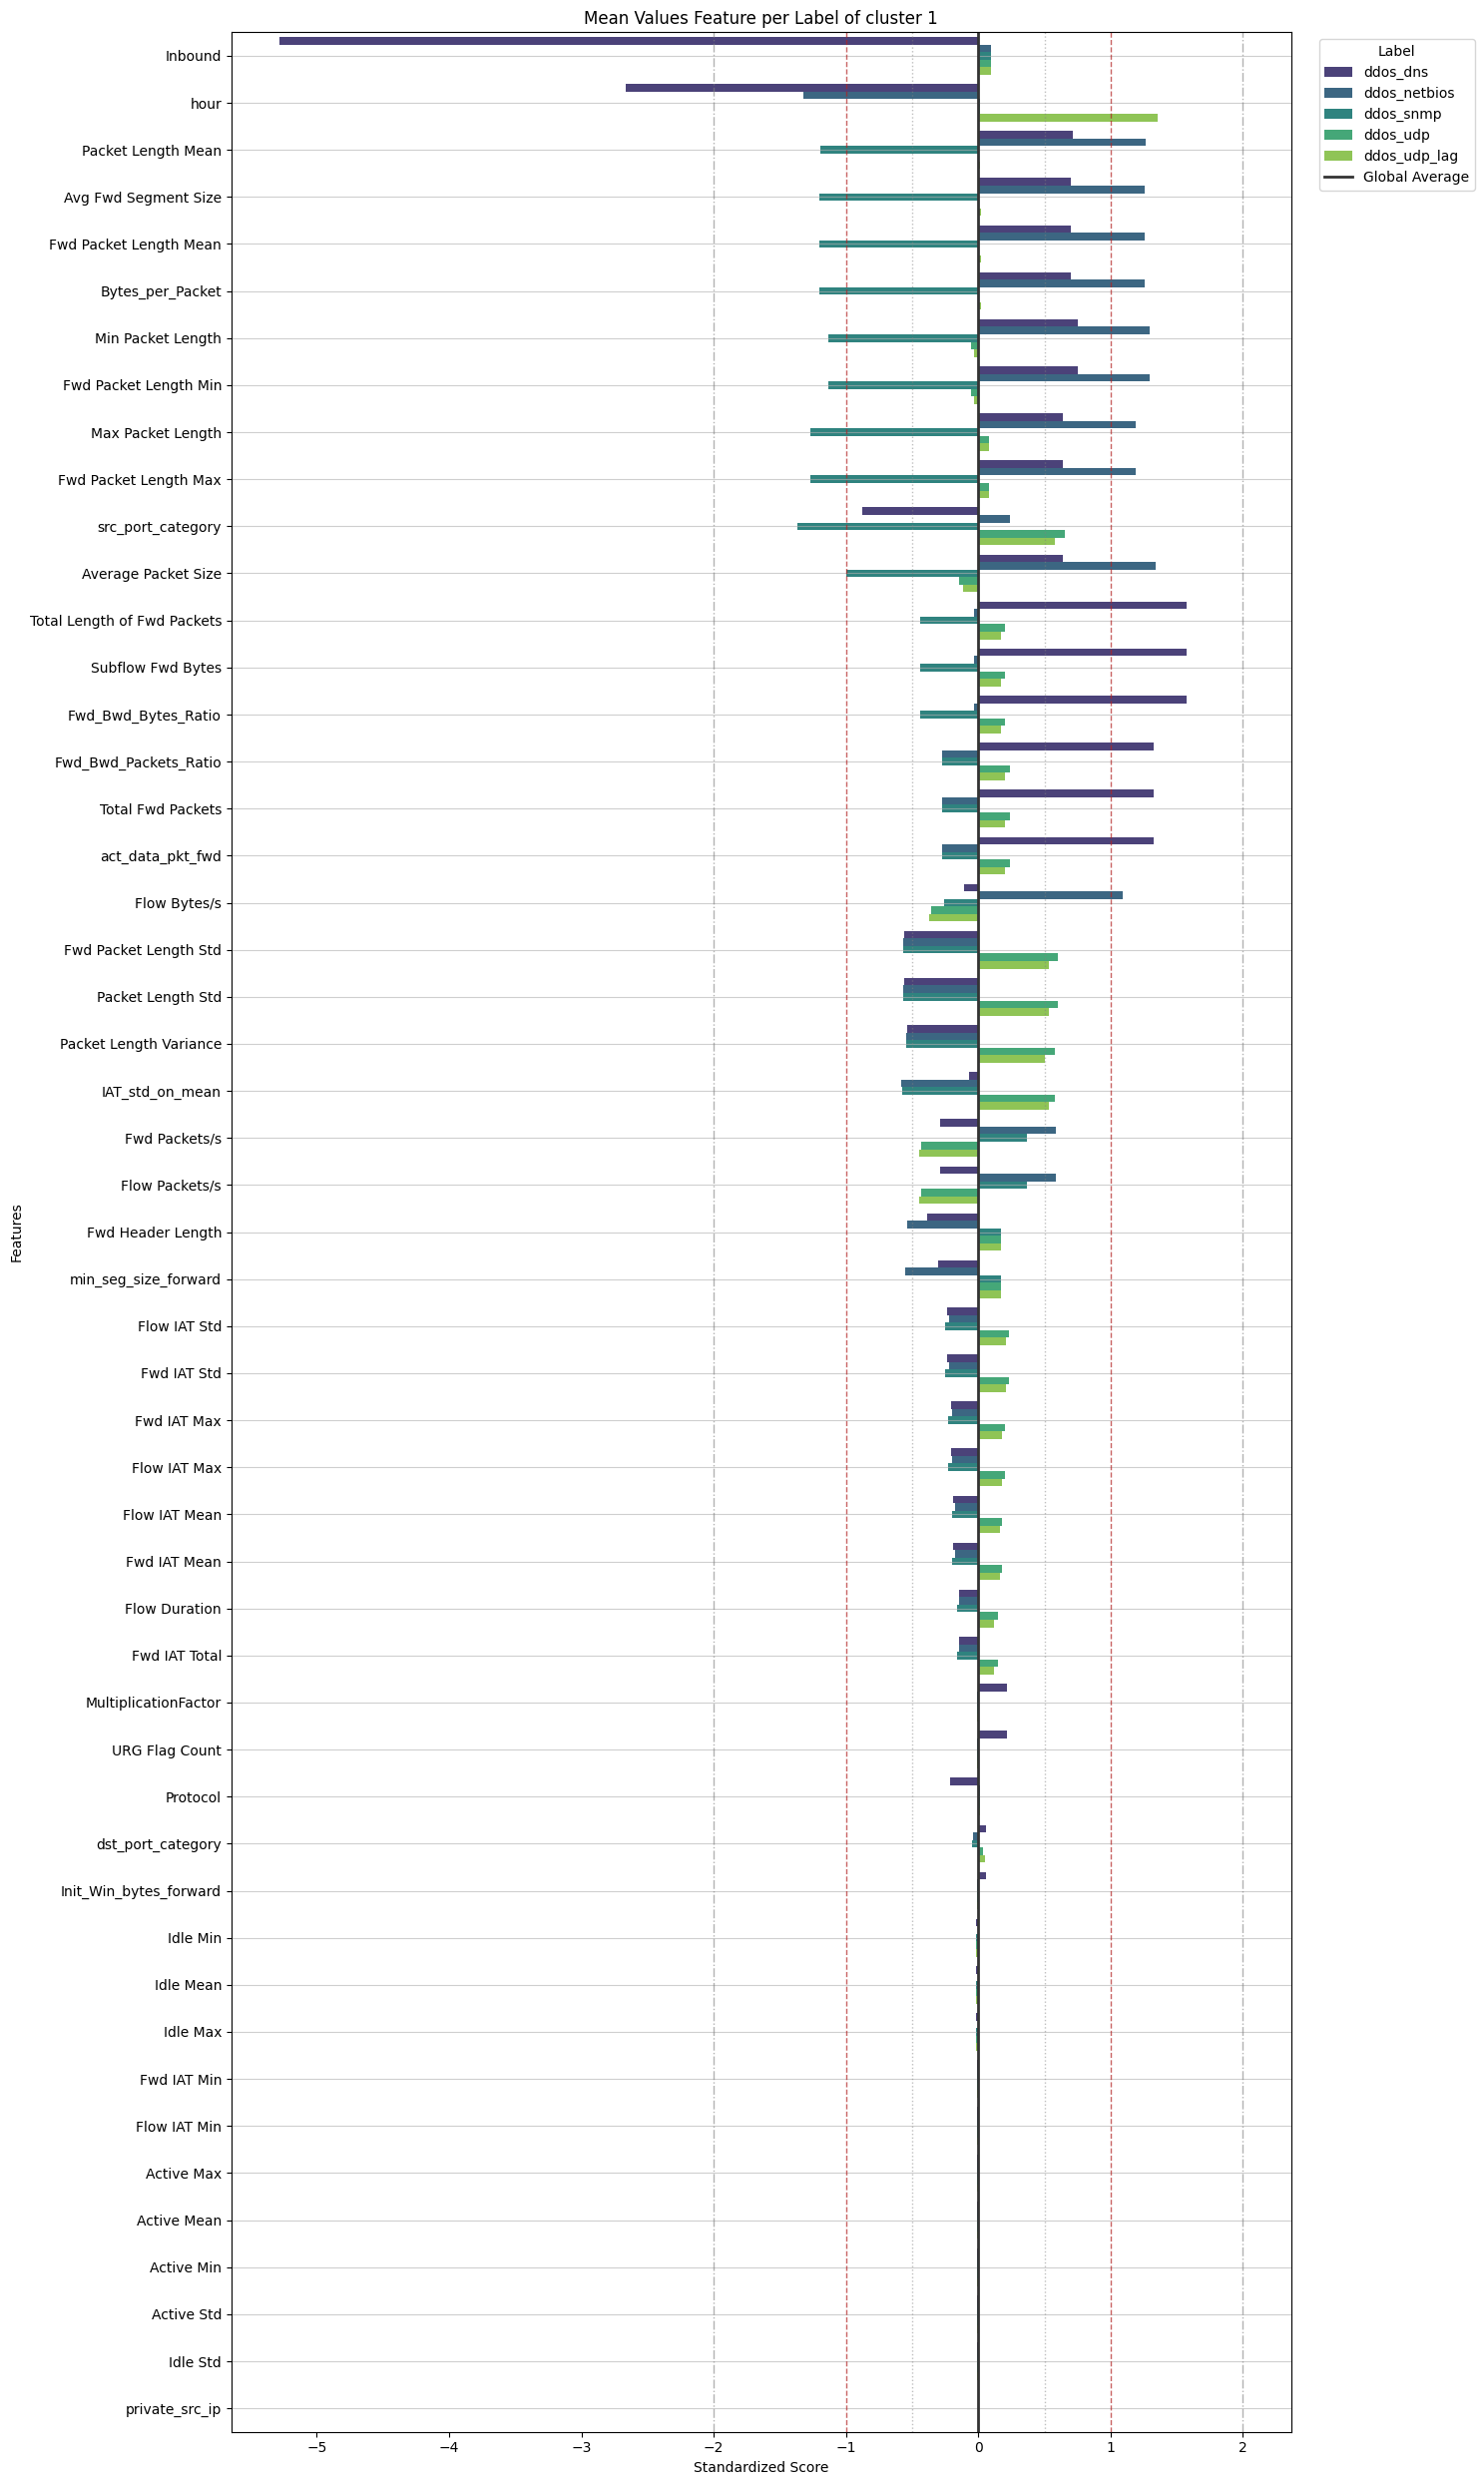

In [83]:
plotMeanFeaturesPerLabel(df_cluster_1_scaled, "Mean", 1)

### Attack Pattern Investigation – cluster 2

In [84]:
df_cluster_2 , df_cluster_2_scaled = getClusterDf(2)

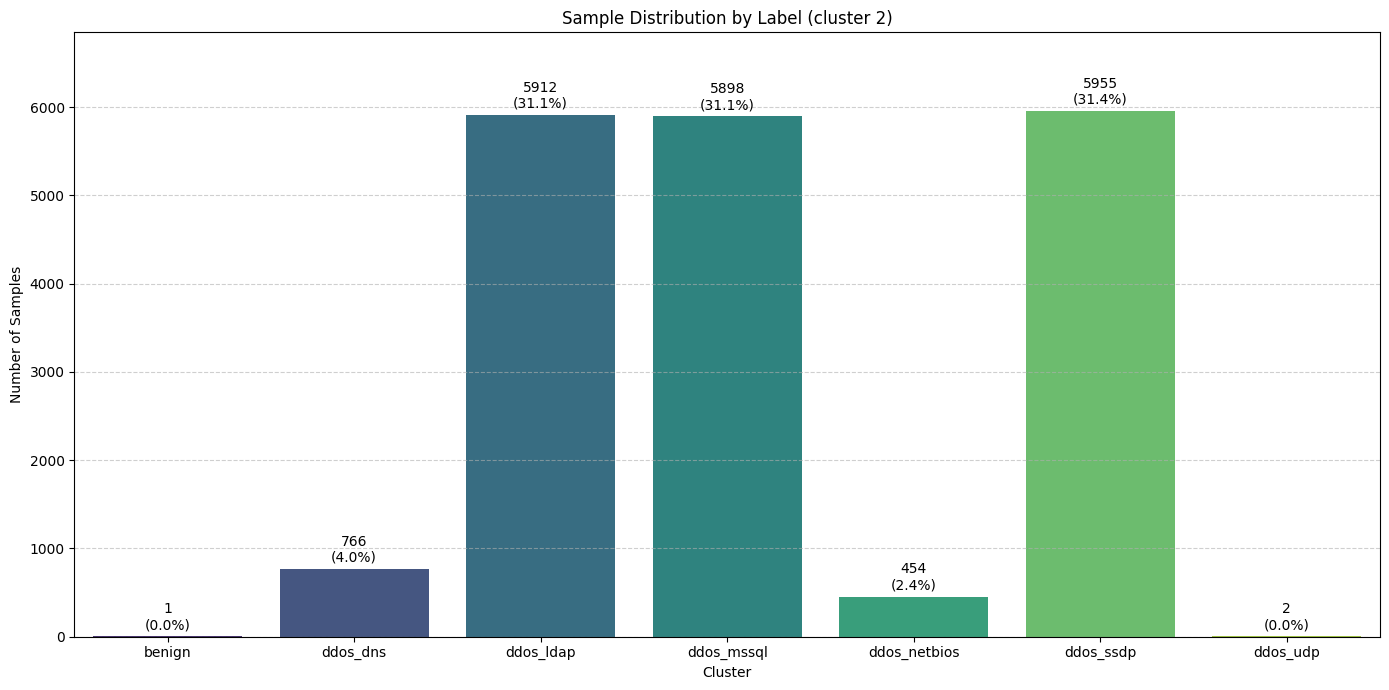

In [85]:
plotLabelSummary(df_cluster_2, 2)

In [86]:
toDrop = ["benign","ddos_udp"]
df_cluster_2 = drop_Labels(df_cluster_2, toDrop)
df_cluster_2_scaled = drop_Labels(df_cluster_2_scaled, toDrop)

In [87]:
df_cluster_2.groupby("label").agg(["mean", "std", "median"])

Protocol             Flow Duration                        \
                 mean  std median          mean            std median   
label                                                                   
ddos_dns         17.0  0.0   17.0    889.041775    3769.647857    2.0   
ddos_ldap        17.0  0.0   17.0      5.126353      20.214660    1.0   
ddos_mssql       17.0  0.0   17.0   5232.820956  283835.662141    1.0   
ddos_netbios     17.0  0.0   17.0      1.574890       3.962003    1.0   
ddos_ssdp        17.0  0.0   17.0    140.301595    7421.115327    2.0   

             Total Fwd Packets                  Total Backward Packets  ...  \
                          mean       std median                   mean  ...   
label                                                                   ...   
ddos_dns              2.248042  0.659641    2.0           1.000000e-12  ...   
ddos_ldap             2.001353  0.104045    2.0           1.000000e-12  ...   
ddos_mssql            2.004069  0.090129    2.0           1.000000e-12  ...   
ddos_netbios          2.000000  0.000000    2.0           1.000000e-12  ...   
ddos_ssdp             2.002687  0.096944    2.0           1.000000e-12  ...   

             src_port_category dst_port_category                   \
                        median              mean       std median   
label                                                               
ddos_dns                   0.0          1.232376  0.422623    1.0   
ddos_ldap                  0.0          1.239682  0.468852    1.0   
ddos_mssql                 0.0          1.239064  0.462044    1.0   
ddos_netbios               1.0          1.202643  0.453967    1.0   
ddos_ssdp                  0.0          1.236272  0.455726    1.0   

             private_src_ip              hour              
                       mean  std median  mean  std median  
label                                                      
ddos_dns                1.0  0.0    1.0  10.0  0.0   10.0  
ddos_ldap               1.0  0.0    1.0  11.0  0.0   11.0  
ddos_mssql              1.0  0.0    1.0  11.0  0.0   11.0  
ddos_netbios            1.0  0.0    1.0  11.0  0.0   11.0  
ddos_ssdp               1.0  0.0    1.0  12.0  0.0   12.0  

[5 rows x 168 columns]

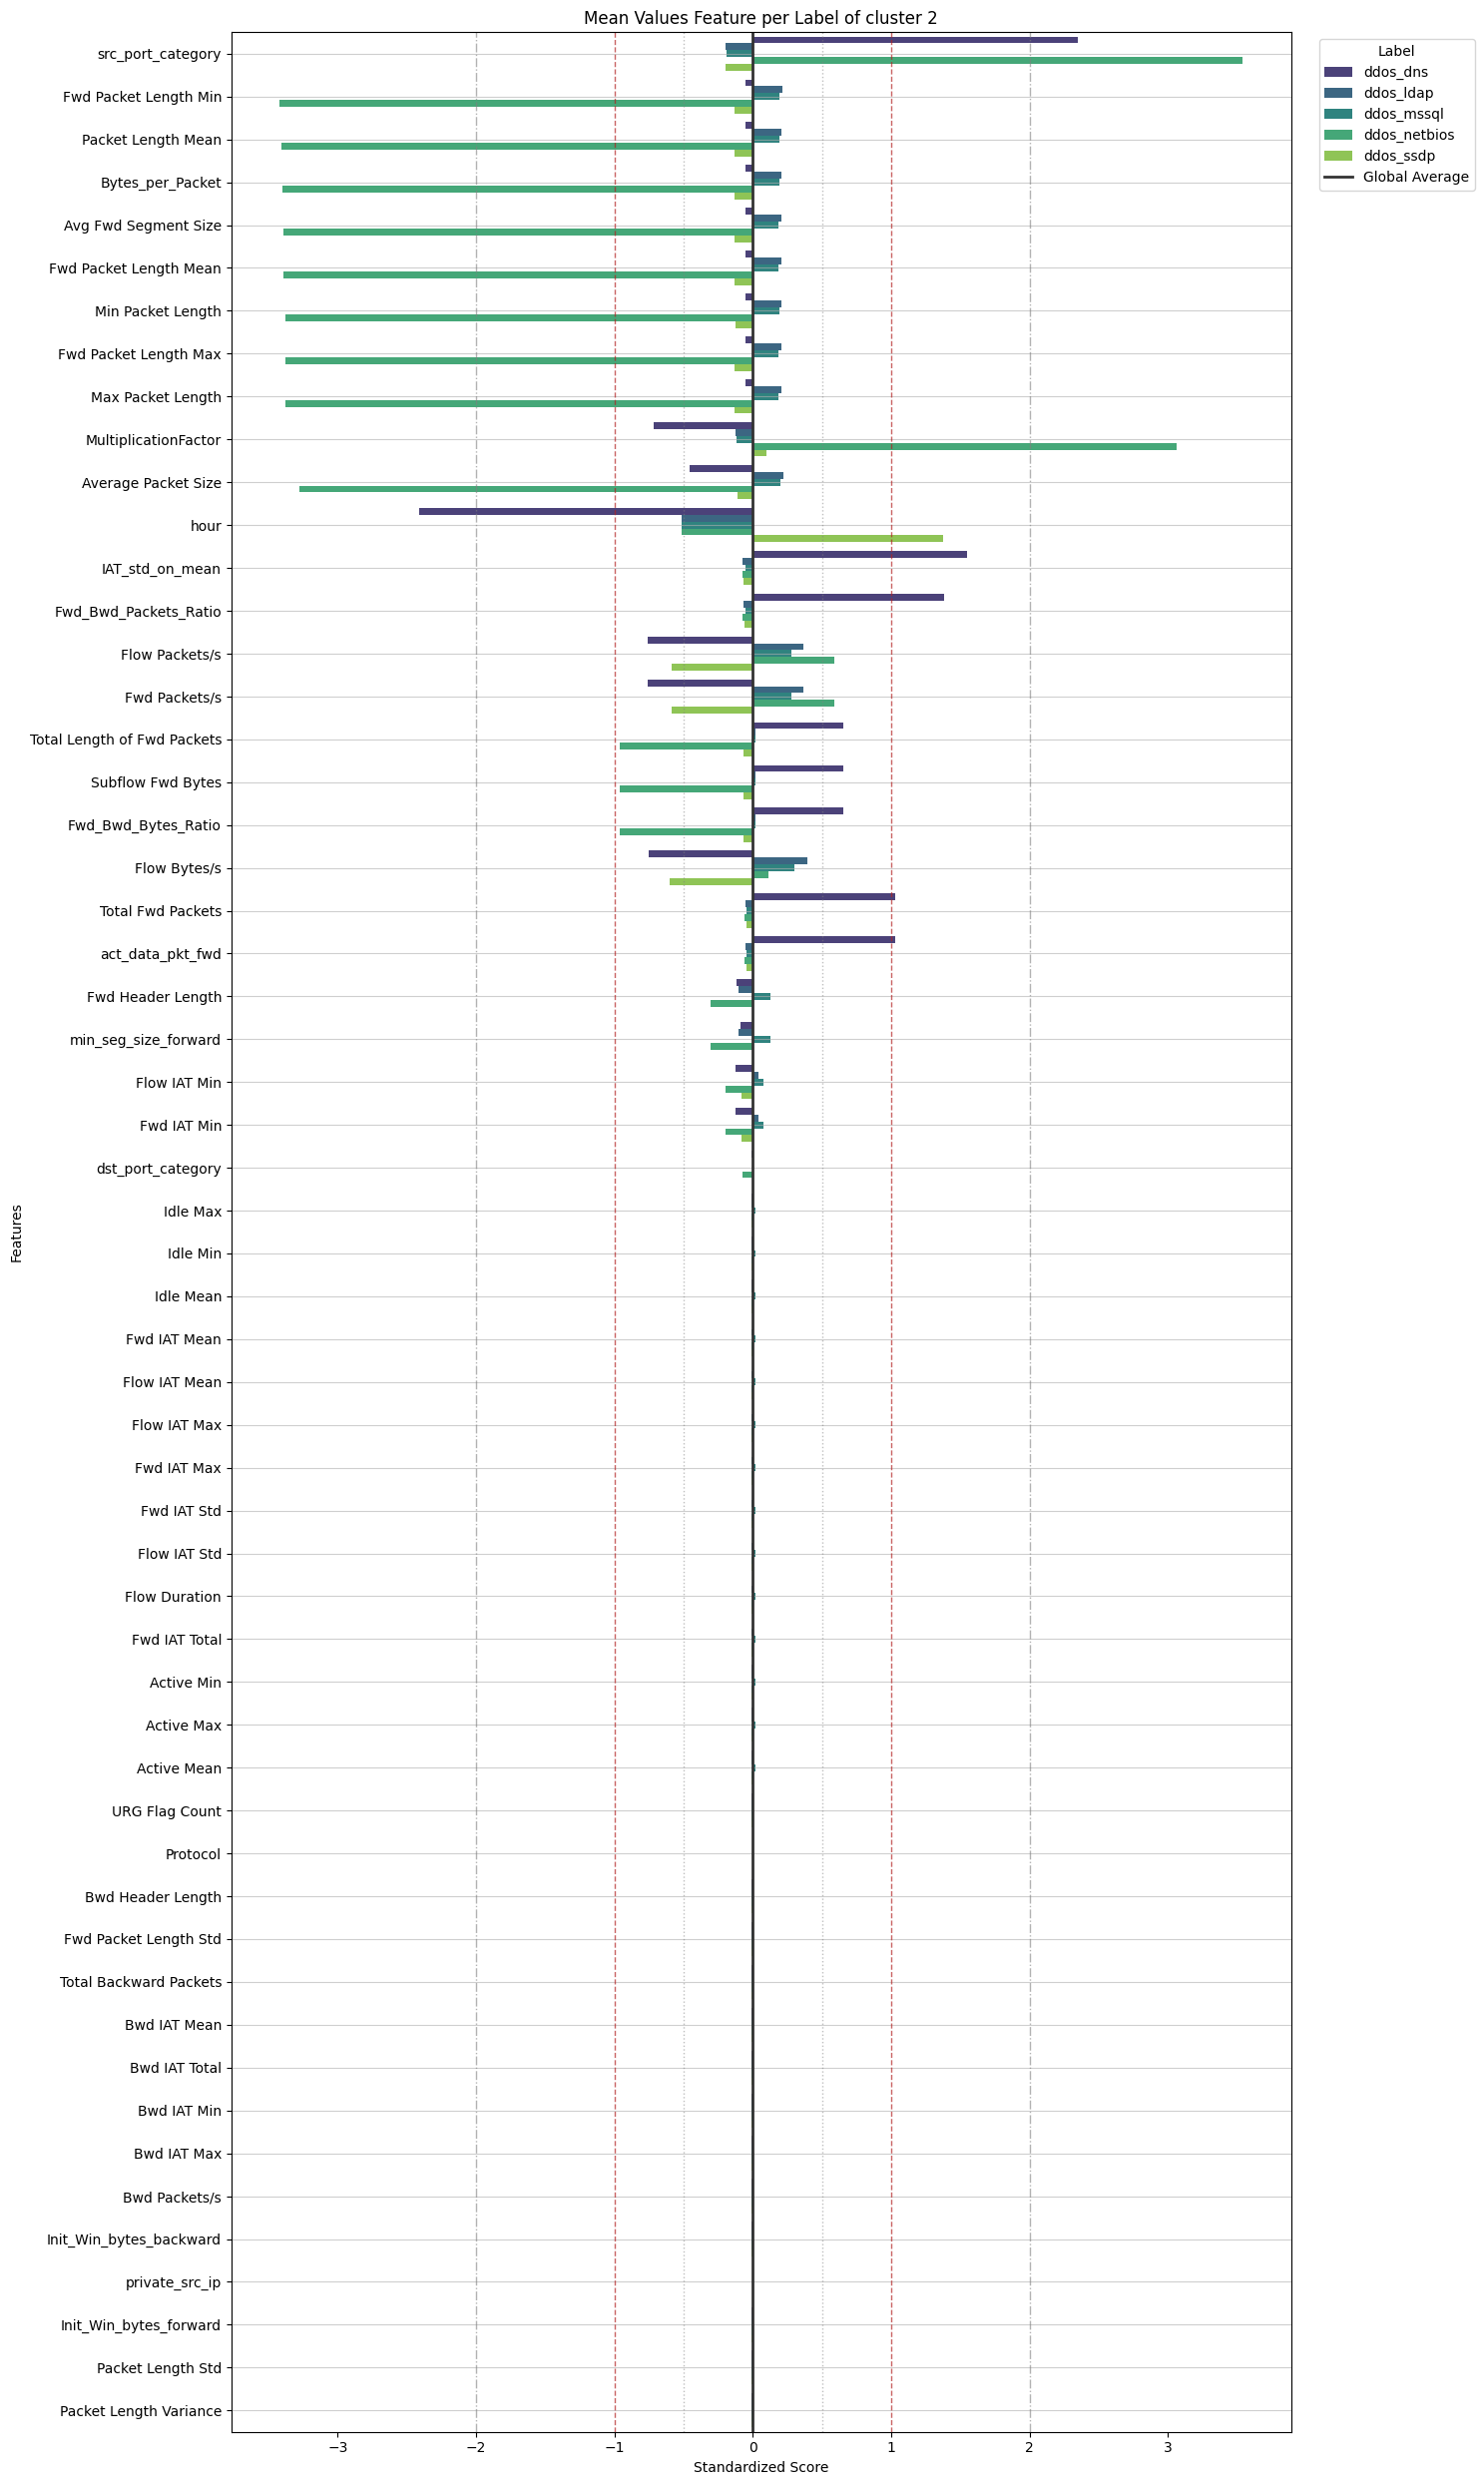

In [88]:
plotMeanFeaturesPerLabel(df_cluster_2_scaled, "Mean", 2)

### Attack Pattern Investigation – cluster 3

In [89]:
df_cluster_3 , df_cluster_3_scaled = getClusterDf(3)

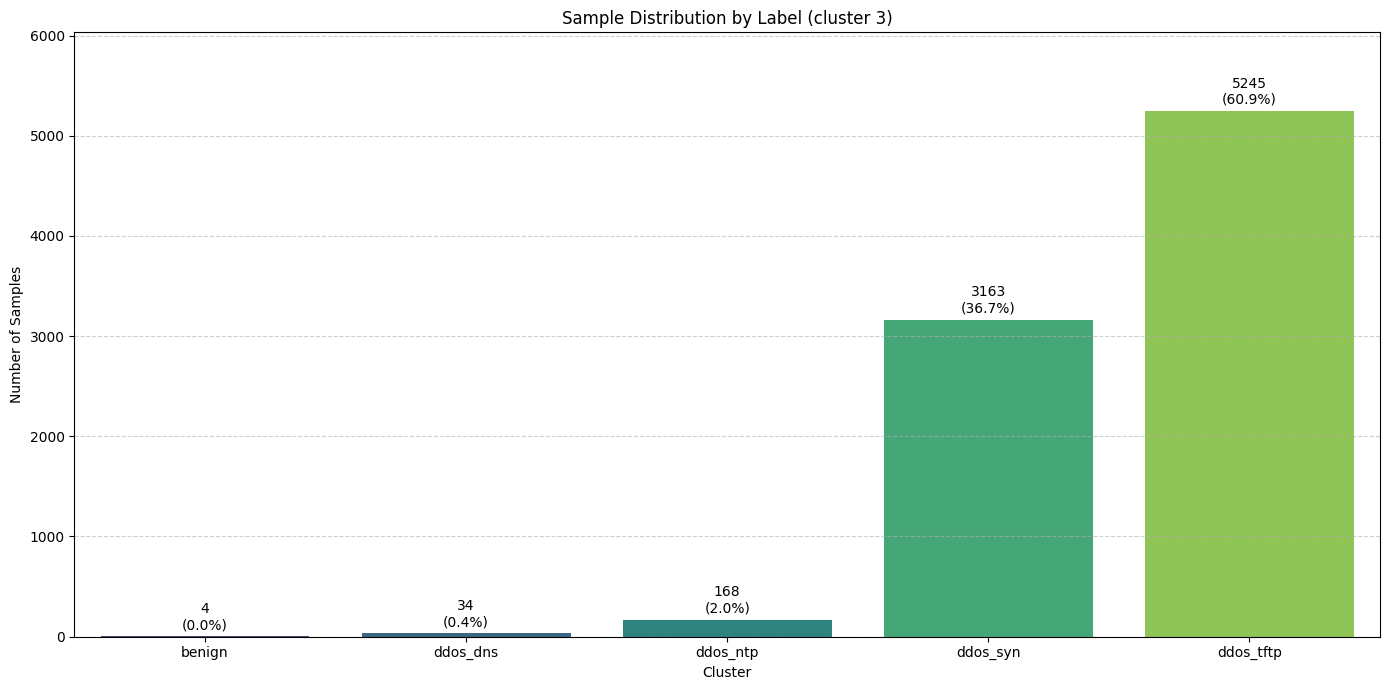

In [90]:
plotLabelSummary(df_cluster_3,3)

In [91]:
toDrop = ["benign","ddos_dns"]
df_cluster_3 = drop_Labels(df_cluster_3, toDrop)
df_cluster_3_scaled = drop_Labels(df_cluster_3_scaled, toDrop)

In [92]:
df_cluster_3.groupby("label").agg(["mean", "std", "median"])

Protocol                  Flow Duration                           \
               mean       std median          mean           std     median   
label                                                                         
ddos_ntp   5.857143  0.917467    6.0  6.807952e+06  6.177751e+06  5447331.5   
ddos_syn   5.998103  0.106685    6.0  4.171466e+04  2.125261e+06        1.0   
ddos_tftp  6.000000  0.000000    6.0  2.290235e+06  4.842382e+06        1.0   

          Total Fwd Packets                   Total Backward Packets  ...  \
                       mean        std median                   mean  ...   
label                                                                 ...   
ddos_ntp          12.172619  11.217500    5.0              12.321429  ...   
ddos_syn           3.387291  77.488520    2.0               0.308568  ...   
ddos_tftp          2.398475   0.814063    2.0               0.277979  ...   

          Fwd_Bwd_Bytes_Ratio src_port_category                   \
                       median              mean       std median   
label                                                              
ddos_ntp                  1.0          1.339286  0.522893    1.0   
ddos_syn                  1.0          1.949099  0.290480    2.0   
ddos_tftp                 1.0          1.104480  0.353350    1.0   

          dst_port_category                   hour              
                       mean       std median  mean  std median  
label                                                           
ddos_ntp           0.226190  0.473266    0.0   9.0  0.0    9.0  
ddos_syn           1.245337  0.470381    1.0  13.0  0.0   13.0  
ddos_tftp          1.240801  0.462736    1.0  13.0  0.0   13.0  

[3 rows x 189 columns]

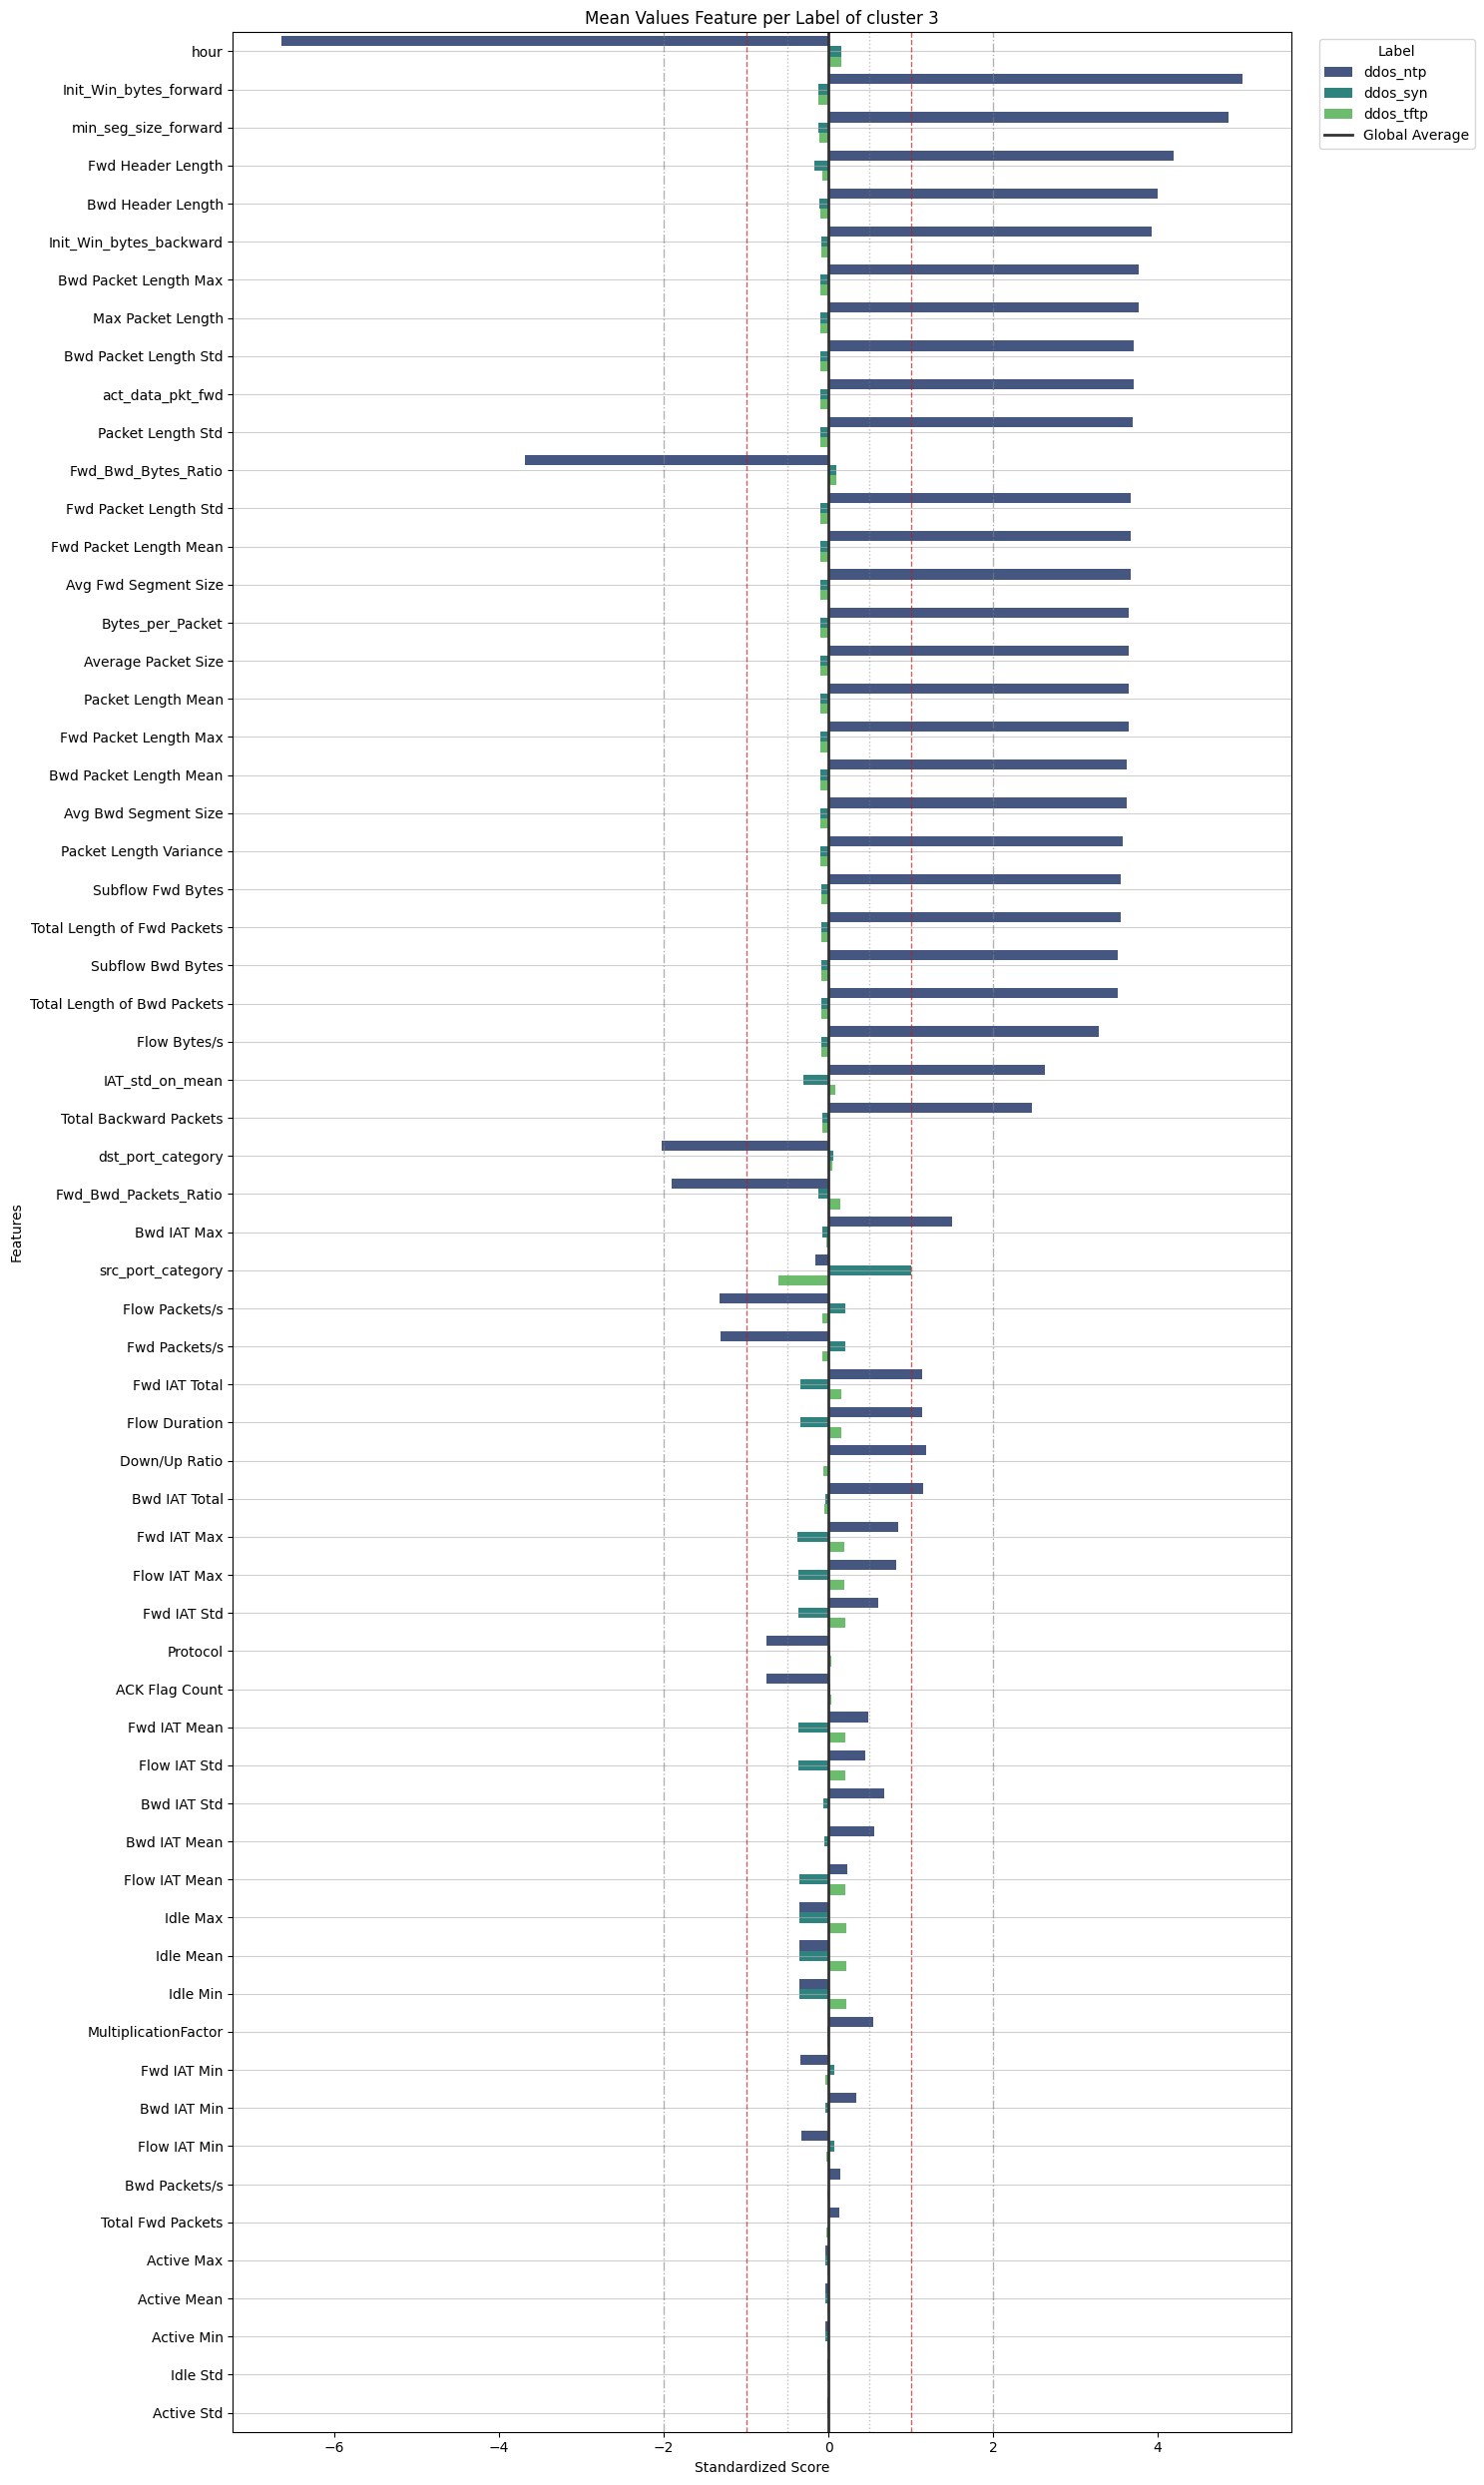

In [93]:
plotMeanFeaturesPerLabel(df_cluster_3_scaled, "Mean", 3)